In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"]="0"


In [3]:
import datasets
import json
import pandas as pd
import numpy as np
from tqdm import tqdm
import copy

In [4]:
from transformers import AutoTokenizer

# Build ManyTypes4Py

### How to get raw data
Load an archive from https://zenodo.org/records/5244636, and unpack it

To obtain train sets, run the code below (up to 16k for train)

### Load initial data

In [4]:
path = "../../data/ManyTypes4PyDataset-v0.7/"

In [5]:
repos = os.listdir(os.path.join(path, "processed_projects_clean"))
repos = [el for el in repos if not(el.startswith("."))]

In [6]:
# train and val splits
df = pd.read_csv(path + "dataset_split.csv")

In [7]:
# TODO:
# 1. split dataset into train and val by repos
# each json file contains one repo with variables, functions (with variables), classes (with variables) and code
# for now, use only variables from main code
# 2. build first split with 2k len by one or more file
# 3. pass

In [8]:
from sklearn.model_selection import train_test_split

train_repos, val_repos = train_test_split(repos, test_size=0.2, random_state=42)
test_repos, val_repos = train_test_split(val_repos, test_size=0.5, random_state=42)

In [119]:
def check_variables(code, variables):
    new_variables = {}
    for variable in variables.keys():
        if variable in code:
            new_variables[variable] = variables[variable]
    return new_variables

In [150]:
import keyword


def filter_consistent_vars(var_type_list):
    new_vars_dict = {}
    stopwords = [".", ",", ";", "=", "==", "_", ">", "<", ")", "(", "]", "[", "!", "?", "[EOL]", "self", "if", "not", "and", "or", "else", "for", "while", "@", "#", "$", "%", "*", "-", "+", "/", "}", "{"]
    for el in var_type_list:
        if keyword.iskeyword(el[0]) or el[0] in stopwords:
            continue
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = None
    new_vars_dict = {key: value.strip("$") for key, value in new_vars_dict.items() if value is not None}
    return new_vars_dict

In [166]:
# process one repo
def extract_repo_data(path, repo):
    repo_path = os.path.join(path, "processed_projects_clean", repo)
    # load repo code
    with open(repo_path, "rb") as f:
        repo_code = json.load(f)
    repo_name = list(repo_code.keys())[0] # check if all repos have one key
    repo_files = list(repo_code[repo_name]['src_files'].keys())
    repo_data = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
    }
    non_match_count = 0
    non_match_len = []
    for fl in repo_files:
        # some code files can be empty
        if len(repo_code[repo_name]['src_files'][fl]["untyped_seq"]) != 0:
            # add check if all variables are in the code

            all_vars = repo_code[repo_name]['src_files'][fl]["untyped_seq"].split(" ")
            all_types = repo_code[repo_name]['src_files'][fl]["typed_seq"].split(" ")
            if len(all_vars) != len(all_types):
                non_match_count += 1
                non_match_len.append(len(all_vars))
                #print(len(all_vars), len(all_types))
                continue
                """
                print(var_type_list)
                print(new_variables)
                print(repo_data["code"][-1])
                for idx in range(min(len(all_vars), len(all_types))):
                    print(all_vars[idx], all_types[idx])
                print(all_vars[min(len(all_vars), len(all_types)):])
                print(all_types[min(len(all_vars), len(all_types)):])
                """
            type_ids = np.where(np.array(all_types) != "0")[0]
            var_type_list = [(all_vars[i], all_types[i]) for i in type_ids]
            new_variables = filter_consistent_vars(var_type_list)
            #print(len(all_vars), len(all_types), len(type_ids))
            
            #assert(len(all_vars) == len(all_types))
            #assert(len(type_ids) == 0)
            #var_type_list = [(all_vars[i], all_types[i]) for i in type_ids]
            #new_variables = filter_consistent_vars(var_type_list)
            repo_data["repo_name"].append(repo_name)
            repo_data["fname"].append(fl)
            repo_data["code"].append(repo_code[repo_name]['src_files'][fl]["untyped_seq"].replace("[EOL] ", "\n").replace("[EOL]", "\n"))
            repo_data["variables"].append(new_variables)
            # add variables from classes and fucntions
            # TODO: add for each variable class and function name (if applicable)
            # Now use only varibales from typed_seq, and omit functions and classes
            """
            if len(repo_code[repo_name]['src_files'][fl]["classes"]) != 0:
                # look for class variables and add them
                for el in repo_code[repo_name]['src_files'][fl]["classes"]:
                    cls_variables = check_variables(repo_code[repo_name]['src_files'][fl]["untyped_seq"],
                                                    el["variables"])
                    repo_data["variables"][-1].update(cls_variables)
            if len(repo_code[repo_name]['src_files'][fl]["funcs"]) != 0:
                # look for class variables and add them
                for el in repo_code[repo_name]['src_files'][fl]["funcs"]:
                    cls_variables = check_variables(repo_code[repo_name]['src_files'][fl]["untyped_seq"],
                                                    el["variables"])
                    repo_data["variables"][-1].update(cls_variables)
            """
    return repo_data, non_match_count, non_match_len



#### Playground

In [342]:
repo = train_repos[3]
repo_path = os.path.join(path, "processed_projects_clean", repo)
# load repo code
with open(repo_path, "rb") as f:
    repo_code = json.load(f)
repo_name = list(repo_code.keys())[0] # check if all repos have one key
repo_files = list(repo_code[repo_name]['src_files'].keys())
repo_data = {
    "repo_name": [],
    "fname": [],
    "code": [],
    "variables": [],
    "types": [],
}
for fl in repo_files:
    # some code files can be empty
    print(fl, repo_files.index(fl))
    if len(repo_code[repo_name]['src_files'][fl]["untyped_seq"]) != 0:
        repo_data["repo_name"].append(repo_name)
        repo_data["fname"].append(fl)
        repo_data["code"].append(repo_code[repo_name]['src_files'][fl]["untyped_seq"])#.replace("[EOL] ", "\n").replace("[EOL]", "\n"))
        repo_data["types"].append(repo_code[repo_name]['src_files'][fl]["typed_seq"])
        # add check if all variables are in the code
        new_variables = check_variables(repo_code[repo_name]['src_files'][fl]["untyped_seq"],
                                        repo_code[repo_name]['src_files'][fl]["variables"])
        repo_data["variables"].append(new_variables)
        # add variables from classes and fucntions
        # TODO: add for each variable class and function name (if applicable)
        if len(repo_code[repo_name]['src_files'][fl]["classes"]) != 0:
            # look for class variables and add them
            for el in repo_code[repo_name]['src_files'][fl]["classes"]:
                cls_variables = check_variables(repo_code[repo_name]['src_files'][fl]["untyped_seq"],
                                                el["variables"])
                print("cls", cls_variables)
                repo_data["variables"][-1].update(cls_variables)
        if len(repo_code[repo_name]['src_files'][fl]["funcs"]) != 0:
            # look for class variables and add them
            for el in repo_code[repo_name]['src_files'][fl]["funcs"]:
                cls_variables = check_variables(repo_code[repo_name]['src_files'][fl]["untyped_seq"],
                                                el["variables"])
                print("func", cls_variables)
                repo_data["variables"][-1].update(cls_variables)

repos/aresik/Cisco_Web_Portal/cisco_web_portal/urls.py 0
repos/aresik/Cisco_Web_Portal/cisco_web_portal/wsgi.py 1
repos/aresik/Cisco_Web_Portal/cisco_web_portal/__init__.py 2
repos/aresik/Cisco_Web_Portal/.venv/bin/miniterm.py 3
cls {}
cls {}
cls {}
cls {}
cls {}
cls {}
cls {}
cls {}
cls {'echo': ''}
cls {}
cls {'echo': ''}
cls {}
cls {}
cls {}
func {}
func {'port': '', 'index': ''}
func {'parser': '', 'group': '', 'args': '', 'filter': '', 'port': '', 'timeout': '', 'dtr': '', 'rts': '', 'miniterm': '', 'raw': ''}
repos/aresik/Cisco_Web_Portal/.venv/bin/django-admin.py 4
repos/aresik/Cisco_Web_Portal/.venv/lib/python3.5/site-packages/mypy_extensions.py 5
cls {'instancecheck': '', 'subclasscheck': ''}
cls {}
cls {}
cls {}
func {}
func {}
func {'total': 'typing.Any', 'field': 'typing.Dict[builtins.str, typing.Any]'}
func {}
func {}
func {}
func {}
func {}
func {}
func {}
repos/aresik/Cisco_Web_Portal/.venv/lib/python3.5/site-packages/pickleshare.py 6
cls {}
cls {}
func {}
func {'usage':

In [343]:
repo_data["repo_name"]

['aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_Portal',
 'aresik/Cisco_Web_P

In [372]:
idx = 7

In [373]:
len(repo_data["code"][idx].split(" "))

2203

In [374]:
len(repo_data["types"][idx].split(" "))

2203

In [375]:
repo_data["types"][idx]

'0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $builtins.str$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $typing.Dict[builtins.str,builtins.int]$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $typing.Dict[builtins.str,typing.List[builtins.str]]$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $typing.Dict[builtins.str,typing.List[builtins.str]]$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $builtins.str$ 0 0 0 $builtins.str$ 0 0 0 0 0 $

In [337]:
type_ids = np.where(np.array(repo_data["types"][idx].split(" ")) != "0")

In [338]:
all_vars = repo_data["code"][idx].split(" ")
all_types = repo_data["types"][idx].split(" ")
type_ids = np.where(np.array(all_types) != "0")[0]
var_type_list = [(all_vars[i], all_types[i]) for i in type_ids]

In [339]:
def filter_consistent_vars(var_type_list):
    new_vars_dict = {}
    for el in var_type_list:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = None
    new_vars_dict = {key: value.strip("$") for key, value in new_vars_dict.items() if value is not None}
    return new_vars_dict

In [340]:
var_type_list.append(('EXCHANGE_NAME', 'builtins.int'))

In [341]:
filter_consistent_vars(var_type_list)

{'EXCHANGE_NAME': 'builtins.int'}

In [332]:
print(repo_data["variables"][idx])

{'model': 'typing.Type[apiqa_storage.models.Attachment]', 'username': 'typing.Type[tests.factories.UserFactory]', 'email': 'typing.Type[tests.factories.UserFactory]', 'name': 'typing.Type[tests.factories.AttachmentFactory]', 'path': 'typing.Type[tests.factories.AttachmentFactory]', 'size': 'typing.Type[tests.factories.AttachmentFactory]', 'data': 'typing.Any'}


In [309]:
print(repo_data["code"][idx].replace("[EOL] ", "\n").replace("[EOL]", "\n"))

import builtins 
from typing import Dict , Union , List , Type , Tuple , Any 
import logging 
import typing 
import files 
import apiqa_storage 
import models 
import logging 
import uuid 
from typing import Union 

from django . utils . translation import ugettext_lazy as _ 
from rest_framework import serializers 
from rest_framework . exceptions import ValidationError 

from . import settings 
from . files import FileInfo , file_info 
from . minio_storage import storage 
from . models import Attachment 
from . validators import file_size_validator 

logger = logging . getLogger ( [string] ) [comment] 


__all__ = [ [string] , [string] ] 


def delete_file ( attach_file_info ) : 
[comment] 
try : 
storage . file_delete ( attach_file_info . path ) 
except Exception : [comment] 
logger . exception ( [string] , attach_file_info . path , storage . bucket_name ) 


class AttachmentSerializer ( serializers . ModelSerializer ) : 
file = serializers . FileField ( write_only = True , required 

#### Build with new variables

In [167]:
# build repo-file level dataset
file_level_data = []
non_match = 0
non_match_lens = []
total_len = 0
for repo in tqdm(train_repos):
    res, non_match_count, non_match_len = extract_repo_data(path, repo)
    non_match_lens += non_match_len
    non_match += non_match_count
    total_len += len(res["code"])
    file_level_data.append(res)

100%|██████████| 4073/4073 [24:44<00:00,  2.74it/s] 


In [168]:
non_match, total_len

(175, 141350)

In [169]:
# concat all file-level data into one dataset
train_ds_dict = copy.deepcopy(file_level_data[0])
for el in tqdm(file_level_data[1:]):
    #for key in train_ds_dict.keys():
    #    train_ds_dict[key].append(el[key])
    train_ds_dict = {key: train_ds_dict[key] + el[key] for key in train_ds_dict.keys()}
# recast variables into tuples for compatibility with hf datasets
train_ds_dict["variables"] = [[(key, value) for key, value in el.items()] for el in train_ds_dict["variables"]]

100%|██████████| 4072/4072 [00:10<00:00, 372.32it/s]


In [170]:
train_ds = datasets.Dataset.from_dict(train_ds_dict)

In [171]:
proc_data = {"train": train_ds}

In [176]:
train_ds

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables'],
    num_rows: 141350
})

In [ ]:
# build repo-file level dataset
repo_names = [val_repos, test_repos]
repo_keys = ["validation", "test"]
for repo_split, repo_key in zip(repo_names, repo_keys):
    print(repo_key)
    file_level_data = []
    for repo in tqdm(repo_split):
        res, non_match_count, non_match_len = extract_repo_data(path, repo)
        non_match_lens += non_match_len
        non_match += non_match_count
        total_len += len(res["code"])
        file_level_data.append(res)
    print(non_match, total_len)
    split_ds_dict = copy.deepcopy(file_level_data[0])
    for el in tqdm(file_level_data[1:]):
        #for key in train_ds_dict.keys():
        #    train_ds_dict[key].append(el[key])
        split_ds_dict = {key: split_ds_dict[key] + el[key] for key in split_ds_dict.keys()}
    split_ds_dict["variables"] = [[(key, value) for key, value in el.items()] for el in split_ds_dict["variables"]]
    proc_data[repo_key] = datasets.Dataset.from_dict(split_ds_dict)

validation


100%|██████████| 510/510 [02:39<00:00,  3.21it/s]


206 159895


100%|██████████| 509/509 [00:00<00:00, 2777.23it/s]


test


  0%|          | 0/509 [00:00<?, ?it/s]

In [179]:
split_ds_dict.keys()

dict_keys(['repo_name', 'fname', 'code', 'variables'])

In [181]:
print(non_match, total_len)
proc_data

221 172510


{'train': Dataset({
     features: ['repo_name', 'fname', 'code', 'variables'],
     num_rows: 141350
 }),
 'validation': Dataset({
     features: ['repo_name', 'fname', 'code', 'variables'],
     num_rows: 18545
 }),
 'test': Dataset({
     features: ['repo_name', 'fname', 'code', 'variables'],
     num_rows: 12615
 })}

In [182]:
manytypes_ds = datasets.DatasetDict(proc_data)
manytypes_ds.save_to_disk("../data/manytypes_raw_v2")

Saving the dataset (0/2 shards):   0%|          | 0/141350 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/18545 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/12615 [00:00<?, ? examples/s]

In [217]:
zero_ids = np.where([len(el["variables"]) for el in manytypes_ds["train"]])

In [219]:
len(zero_ids[0])

70371

In [376]:
manytypes_ds["train"][0]

{'repo_name': 'improbable-research/keanu',
 'fname': 'repos/improbable-research/keanu/keanu-python/setup.py',
 'code': 'from typing import Any , Dict \nimport builtins \nimport typing \nfrom setuptools import setup , find_packages \nimport shutil \nimport os \n\n\ndef readme ( ) : \nwith open ( [string] , [string] ) as f : \nreturn f . read ( ) \n\n\nhere = os . path . abspath ( os . path . dirname ( __file__ ) ) \nabout = { } \nwith open ( os . path . join ( here , [string] , [string] ) , [string] , encoding = [string] ) as f : \nexec ( f . read ( ) , about ) \n\n[comment] \nfor dir_name in ( [string] % about [ [string] ] , [string] , [string] , [string] ) : \nshutil . rmtree ( dir_name , ignore_errors = True ) \n\nsetup ( name = [string] , description = [string] , long_description = readme ( ) , version = about [ [string] ] , author = [string] , author_email = [string] , url = [string] , license = [string] , packages = find_packages ( exclude = [ [string] ] ) , include_package_data =

### Load raw dataset, filter, rebuild

In [94]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw")

In [4]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [5]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [97]:
manytypes_ds = manytypes_ds.map(caclulate_length)

Map:   0%|          | 0/12630 [00:00<?, ? examples/s]

In [98]:
tr_lens = manytypes_ds["train"]["length"]
np.mean(tr_lens), np.percentile(tr_lens, 10), np.percentile(tr_lens, 20), np.percentile(tr_lens, 80), np.percentile(tr_lens, 95)

(np.float64(1020.0314856032503),
 np.float64(41.0),
 np.float64(72.0),
 np.float64(997.0),
 np.float64(3262.0))

In [99]:
def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(curr_vars)
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [100]:
all_repos = {}
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], 0, 2048)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, 0, 2048)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:11<00:00, 43.23it/s]


In [101]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [102]:
code_repos_2k = datasets.DatasetDict(all_repos)

In [103]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [104]:
# filter samples with empty variables
code_repos_2k = code_repos_2k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/56927 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6982 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5182 [00:00<?, ? examples/s]

In [139]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_2k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/31548 [00:00<?, ? examples/s]

Map:   0%|          | 0/4327 [00:00<?, ? examples/s]

Map:   0%|          | 0/3274 [00:00<?, ? examples/s]

100%|██████████| 3274/3274 [00:00<00:00, 4963.25it/s]


In [145]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [141]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [146]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/232994 [00:00<?, ? examples/s]

Map:   0%|          | 0/35886 [00:00<?, ? examples/s]

Map:   0%|          | 0/23529 [00:00<?, ? examples/s]

In [147]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [148]:
flatten_dataset_2k.save_to_disk("../data/manytypes_flat_stacked_0k_2k")

Saving the dataset (0/5 shards):   0%|          | 0/232994 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/35886 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/23529 [00:00<?, ? examples/s]

In [150]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 1920)

Filter:   0%|          | 0/232994 [00:00<?, ? examples/s]

Filter:   0%|          | 0/35886 [00:00<?, ? examples/s]

Filter:   0%|          | 0/23529 [00:00<?, ? examples/s]

In [151]:
flatten_dataset_2k_filtered.save_to_disk("../data/manytypes_flat_stacked_0k_2k")

Saving the dataset (0/3 shards):   0%|          | 0/136284 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/14918 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/14697 [00:00<?, ? examples/s]

In [ ]:
# now tokenize and calc length

In [ ]:
flatten_dataset_2k.save_to_disk("../data/manytypes_flat_stacked_0k_2k")

In [152]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/136284 [00:00<?, ? examples/s]

Filter:   0%|          | 0/14918 [00:00<?, ? examples/s]

Filter:   0%|          | 0/14697 [00:00<?, ? examples/s]

In [154]:
flatten_dataset_2k_filtered_empty.save_to_disk("../data/manytypes_flat_stacked_no_empty_0k_2k")

Saving the dataset (0/2 shards):   0%|          | 0/112079 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/12510 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/11973 [00:00<?, ? examples/s]

In [63]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../data/manytypes_flat_stacked_no_empty_0k_2k")


In [64]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 112079
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 12510
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 11973
    })
})

In [66]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [68]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared/manytypes_flat_stacked_no_empty_sv_0k_2k")

Saving the dataset (0/1 shards):   0%|          | 0/112079 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1251 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/11973 [00:00<?, ? examples/s]

In [39]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared/manytypes_flat_stacked_no_empty_0k_2k")

Saving the dataset (0/1 shards):   0%|          | 0/112079 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/12510 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/11973 [00:00<?, ? examples/s]

In [14]:
flatten_dataset_2k_filtered_empty["validation"]["answer"][0]

'builtins.str'

In [15]:
test_answs = flatten_dataset_2k_filtered_empty["validation"]["answer"]

In [17]:
unique_answs = np.unique(test_answs, return_counts=True)

In [37]:
test_answs_ids = np.argsort(unique_answs[1])[::-1][200:]
unique_answs[1][test_answs_ids], unique_answs[0][test_answs_ids]

(array([3, 3, 3, ..., 1, 1, 1], shape=(1304,)),
 array(['typing.Optional[builtins.bytes]',
        'typing.List[typing.Union[typing.Dict[builtins.str, builtins.str], typing.Tuple[builtins.str, builtins.str, builtins.int, builtins.bool]]]',
        'wemake_python_styleguide.visitors.ast.loops.WrongComprehensionVisitor',
        ..., 'UserStatus', 'aiko.utils.ProxyAttr',
        'aiko.application.Application'], shape=(1304,), dtype='<U661'))

### Manytypes on 512 length

In [4]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw")

In [5]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [6]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [7]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [8]:
def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(curr_vars)
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [9]:
all_repos = {}
min_len = 0
max_len = 512
split_suffix = "512"
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:12<00:00, 42.02it/s]


In [10]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [11]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [12]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [13]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/93591 [00:00<?, ? examples/s]

Filter:   0%|          | 0/12020 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8307 [00:00<?, ? examples/s]

In [14]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/45204 [00:00<?, ? examples/s]

Map:   0%|          | 0/6635 [00:00<?, ? examples/s]

Map:   0%|          | 0/4782 [00:00<?, ? examples/s]

100%|██████████| 4782/4782 [00:00<00:00, 8169.32it/s]


In [15]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [16]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [17]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/226440 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (140522 > 131072). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/34942 [00:00<?, ? examples/s]

Map:   0%|          | 0/22840 [00:00<?, ? examples/s]

In [18]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [19]:
flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

Saving the dataset (0/4 shards):   0%|          | 0/226440 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/34942 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/22840 [00:00<?, ? examples/s]

In [20]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < max_len-64)

Filter:   0%|          | 0/226440 [00:00<?, ? examples/s]

Filter:   0%|          | 0/34942 [00:00<?, ? examples/s]

Filter:   0%|          | 0/22840 [00:00<?, ? examples/s]

In [21]:
flatten_dataset_2k_filtered.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

Saving the dataset (0/1 shards):   0%|          | 0/39646 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5278 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/4854 [00:00<?, ? examples/s]

In [22]:
# now tokenize and calc length

In [23]:
flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

Saving the dataset (0/4 shards):   0%|          | 0/226440 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/34942 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/22840 [00:00<?, ? examples/s]

In [24]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/39646 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5278 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4854 [00:00<?, ? examples/s]

In [25]:
flatten_dataset_2k_filtered_empty.save_to_disk(f"../../data/mt_prepared/manytypes_flat_stacked_no_empty_0k_{split_suffix}")

Saving the dataset (0/1 shards):   0%|          | 0/35224 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/4708 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/4269 [00:00<?, ? examples/s]

In [26]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk(f"../../data/mt_prepared/manytypes_flat_stacked_no_empty_0k_{split_suffix}")


In [27]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 35224
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 4708
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 4269
    })
})

In [28]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [29]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk(f"../../data/mt_prepared/manytypes_flat_stacked_no_empty_sv_0k_{split_suffix}")

Saving the dataset (0/1 shards):   0%|          | 0/35224 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/470 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/4269 [00:00<?, ? examples/s]

### Manytypes on 1k length

In [529]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [530]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [531]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [532]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [533]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [534]:
all_repos = {}
min_len = 0
max_len = 1024
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:12<00:00, 39.68it/s]


In [535]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [536]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [537]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [538]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/75185 [00:00<?, ? examples/s]

Filter:   0%|          | 0/10591 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6433 [00:00<?, ? examples/s]

In [539]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/47467 [00:00<?, ? examples/s]

Map:   0%|          | 0/7088 [00:00<?, ? examples/s]

Map:   0%|          | 0/5131 [00:00<?, ? examples/s]

100%|██████████| 5131/5131 [00:01<00:00, 4855.18it/s]


In [540]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [541]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/447973 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (140522 > 131072). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/70690 [00:00<?, ? examples/s]

Map:   0%|          | 0/47307 [00:00<?, ? examples/s]

In [ ]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [ ]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 960)

Filter:   0%|          | 0/447973 [00:00<?, ? examples/s]

Filter:   0%|          | 0/70690 [00:00<?, ? examples/s]

Filter:   0%|          | 0/47307 [00:00<?, ? examples/s]

In [ ]:
#flatten_dataset_2k_filtered.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
# now tokenize and calc length

In [ ]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/141295 [00:00<?, ? examples/s]

Filter:   0%|          | 0/18796 [00:00<?, ? examples/s]

Filter:   0%|          | 0/15926 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_1k")

Saving the dataset (0/3 shards):   0%|          | 0/141295 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/18796 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/15926 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_1k")


In [ ]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 141295
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 18796
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 15926
    })
})

In [ ]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [ ]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_1k")

Saving the dataset (0/1 shards):   0%|          | 0/141295 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1879 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/15926 [00:00<?, ? examples/s]

### Manytypes on 512 length

In [5]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [6]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [7]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [8]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [9]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [10]:
all_repos = {}
min_len = 0
max_len = 512
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:08<00:00, 57.41it/s]


In [11]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [12]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [13]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [14]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/93203 [00:00<?, ? examples/s]

Filter:   0%|          | 0/12308 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8258 [00:00<?, ? examples/s]

In [15]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/56684 [00:00<?, ? examples/s]

Map:   0%|          | 0/8322 [00:00<?, ? examples/s]

Map:   0%|          | 0/6242 [00:00<?, ? examples/s]

100%|██████████| 6242/6242 [00:00<00:00, 9367.27it/s]


In [16]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [17]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [18]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/455925 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (140522 > 131072). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/71795 [00:00<?, ? examples/s]

Map:   0%|          | 0/48008 [00:00<?, ? examples/s]

In [19]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [20]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [21]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 512-64)

Filter:   0%|          | 0/455925 [00:00<?, ? examples/s]

Filter:   0%|          | 0/71795 [00:00<?, ? examples/s]

Filter:   0%|          | 0/48008 [00:00<?, ? examples/s]

In [22]:
#flatten_dataset_2k_filtered.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [23]:
# now tokenize and calc length

In [24]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [25]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/60836 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8431 [00:00<?, ? examples/s]

Filter:   0%|          | 0/7058 [00:00<?, ? examples/s]

In [26]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_512")

Saving the dataset (0/2 shards):   0%|          | 0/60836 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/8431 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7058 [00:00<?, ? examples/s]

In [27]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_512")


In [28]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 60836
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 8431
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 7058
    })
})

In [29]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [30]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_512")

Saving the dataset (0/1 shards):   0%|          | 0/60836 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/843 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/7058 [00:00<?, ? examples/s]

### Manytypes on 256 length

In [31]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [32]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [33]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [34]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [35]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [36]:
all_repos = {}
min_len = 0
max_len = 256
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:08<00:00, 57.58it/s]


In [37]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [38]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [39]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [40]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/110180 [00:00<?, ? examples/s]

Filter:   0%|          | 0/13793 [00:00<?, ? examples/s]

Filter:   0%|          | 0/9775 [00:00<?, ? examples/s]

In [41]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/63405 [00:00<?, ? examples/s]

Map:   0%|          | 0/8911 [00:00<?, ? examples/s]

Map:   0%|          | 0/6966 [00:00<?, ? examples/s]

100%|██████████| 6966/6966 [00:00<00:00, 8389.31it/s]


In [42]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [43]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/460114 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (140522 > 131072). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/72068 [00:00<?, ? examples/s]

Map:   0%|          | 0/48460 [00:00<?, ? examples/s]

In [ ]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [ ]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 256-64)

Filter:   0%|          | 0/460114 [00:00<?, ? examples/s]

Filter:   0%|          | 0/72068 [00:00<?, ? examples/s]

Filter:   0%|          | 0/48460 [00:00<?, ? examples/s]

In [ ]:
#flatten_dataset_2k_filtered.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
# now tokenize and calc length

In [ ]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/16196 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1910 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1747 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_256")

Saving the dataset (0/1 shards):   0%|          | 0/16196 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1910 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1747 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_256")


In [ ]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 16196
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 1910
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 1747
    })
})

In [ ]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [ ]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_256")

Saving the dataset (0/1 shards):   0%|          | 0/16196 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/191 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1747 [00:00<?, ? examples/s]

### Manytypes on 2k length

In [ ]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [ ]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [ ]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [ ]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [ ]:
all_repos = {}
min_len = 0
max_len = 2048
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:12<00:00, 40.26it/s]


In [ ]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [ ]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [ ]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [ ]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/56411 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8617 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4639 [00:00<?, ? examples/s]

In [ ]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/37547 [00:00<?, ? examples/s]

Map:   0%|          | 0/5884 [00:00<?, ? examples/s]

Map:   0%|          | 0/3843 [00:00<?, ? examples/s]

100%|██████████| 3843/3843 [00:01<00:00, 3771.49it/s]


In [ ]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [ ]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/437567 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (140522 > 131072). Running this sequence through the model will result in indexing errors


In [ ]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [ ]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 1920)

In [ ]:
#flatten_dataset_2k_filtered.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
# now tokenize and calc length

In [ ]:
#flatten_dataset_2k.save_to_disk("../../data/mt_intermediate/manytypes_flat_stacked_0k_1k")

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_2k")

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_2k")


In [ ]:
flatten_dataset_2k_filtered_empty

In [ ]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [ ]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_2k")

### Manytypes on 4k length

In [ ]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [ ]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [ ]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [ ]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [ ]:
all_repos = {}
min_len = 0
max_len = 4096
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


In [ ]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [ ]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [ ]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [ ]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

In [ ]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

In [ ]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [ ]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/67899 [00:00<?, ? examples/s]

Map:   0%|          | 0/44932 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 1920*2)

Filter:   0%|          | 0/423355 [00:00<?, ? examples/s]

Filter:   0%|          | 0/67899 [00:00<?, ? examples/s]

Filter:   0%|          | 0/44932 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/289205 [00:00<?, ? examples/s]

Filter:   0%|          | 0/44652 [00:00<?, ? examples/s]

Filter:   0%|          | 0/31996 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_4k")

Saving the dataset (0/9 shards):   0%|          | 0/289205 [00:00<?, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/44652 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/31996 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_4k")


In [ ]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 289205
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 44652
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 31996
    })
})

In [ ]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [ ]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_4k")

Saving the dataset (0/5 shards):   0%|          | 0/289205 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/4465 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/31996 [00:00<?, ? examples/s]

In [609]:
x = 0

### Manytypes on 8k length

In [ ]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [ ]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [ ]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [ ]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [ ]:
all_repos = {}
min_len = 0
max_len = 4096*2
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:12<00:00, 39.71it/s]


In [ ]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [ ]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [ ]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [ ]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/31118 [00:00<?, ? examples/s]

Filter:   0%|          | 0/4439 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2538 [00:00<?, ? examples/s]

In [ ]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/20861 [00:00<?, ? examples/s]

Map:   0%|          | 0/3468 [00:00<?, ? examples/s]

Map:   0%|          | 0/2212 [00:00<?, ? examples/s]

100%|██████████| 2212/2212 [00:01<00:00, 1677.71it/s]


In [ ]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [ ]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/407959 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (3117437 > 131072). Running this sequence through the model will result in indexing errors


Map:   0%|          | 0/43039 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 1920*4)

Filter:   0%|          | 0/407959 [00:00<?, ? examples/s]

Filter:   0%|          | 0/65544 [00:00<?, ? examples/s]

Filter:   0%|          | 0/43039 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/328257 [00:00<?, ? examples/s]

Filter:   0%|          | 0/51310 [00:00<?, ? examples/s]

Filter:   0%|          | 0/34690 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_8k")

Saving the dataset (0/14 shards):   0%|          | 0/328257 [00:00<?, ? examples/s]

Saving the dataset (0/3 shards):   0%|          | 0/51310 [00:00<?, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/34690 [00:00<?, ? examples/s]

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_8k")


In [ ]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 328257
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 51310
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 34690
    })
})

In [ ]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [ ]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k")

Saving the dataset (0/10 shards):   0%|          | 0/328257 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/5131 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/34690 [00:00<?, ? examples/s]

### Manytypes on 16k length

In [ ]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [ ]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [ ]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [ ]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [ ]:
all_repos = {}
min_len = 0
max_len = 4096*4
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:12<00:00, 38.94it/s]


In [ ]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [ ]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [ ]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [ ]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/21560 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3626 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1807 [00:00<?, ? examples/s]

In [ ]:
# generate prompts and answers, and recalc length
multi_code_repos_2k = code_repos_4k.map(flatten_samples)
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds

Map:   0%|          | 0/14330 [00:00<?, ? examples/s]

Map:   0%|          | 0/2672 [00:00<?, ? examples/s]

Map:   0%|          | 0/1551 [00:00<?, ? examples/s]

100%|██████████| 1551/1551 [00:01<00:00, 832.84it/s]


In [ ]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [ ]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/390265 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (3123268 > 131072). Running this sequence through the model will result in indexing errors


In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < 1920*8)

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_16k")

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_16k")


In [ ]:
flatten_dataset_2k_filtered_empty

In [ ]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [ ]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_16k")

### Manytypes on 64k length, only test, 100 per split

In [870]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [871]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [872]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [873]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [874]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [875]:
all_repos = {}
# for v2
min_len = 16 * 1024
# for v3
min_len = 0 * 1024
max_len = 64 * 1024
split_suffix = "0k_64k_v3"
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:13<00:00, 38.59it/s]


In [876]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [877]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [878]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [879]:
def flatten_samples_batched(example):
    print(type(example))
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [880]:
def flatten_samples_dataset(ds):
    sub_ds = []
    for idx in tqdm(range(len(ds))):
        example = ds[idx]
        prompt_template = lambda variable: f"What is the type of variable {variable}?"
        new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
        new_examples["answer"] = []
        for v in example["variables"]:
            for key in new_examples.keys():
                if key == "variables":
                    new_examples[key].append(prompt_template(v[0]))
                    new_examples["answer"].append(v[1])
                elif key == "answer":
                    pass
                else:
                    new_examples[key].append(example[key])
        sub_ds.append(datasets.Dataset.from_dict(new_examples))
    return datasets.concatenate_datasets(sub_ds)

In [881]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/9145 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1421 [00:00<?, ? examples/s]

Filter:   0%|          | 0/885 [00:00<?, ? examples/s]

In [882]:
code_repos_4k["test"][0]

{'repo_name': '0hoo/snowball',
 'fname': ['repos/0hoo/snowball/core_sample.py',
  'repos/0hoo/snowball/setup.py',
  'repos/0hoo/snowball/test.py',
  'repos/0hoo/snowball/app.py'],
 'code': 'from typing import List , Any \nimport typing \nimport requests \nfrom lxml import html \n\n\nDAUM_BASIC = [string] \nNAVER_COMPANY = [string] \nNAVER_YEARLY = [string] \n\n\ndef basic ( code ) : \nurl = DAUM_BASIC + code \ncontent = requests . get ( url ) . content \ntree = html . fromstring ( content ) \ntitle = tree . xpath ( [string] ) [ [number] ] . text \nprice = tree . xpath ( [string] ) [ [number] ] . text \nprice = float ( price . replace ( [string] , [string] ) ) \n\nreturn ( title , price ) \n\n\ndef bps ( code ) : \nurl = [string] + code \ncontent = requests . get ( url ) . content \ntree = html . fromstring ( content ) \n\nbps = tree . xpath ( [string] ) [ [number] ] . text \nbps = int ( bps . replace ( [string] , [string] ) ) \nreturn bps \n\n\ndef snowball ( code ) : \nurl = NAVER_YEA

In [883]:
multi_code_repos_2k["test"]

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length', 'answer'],
    num_rows: 37535
})

In [884]:
# generate prompts and answers, and recalc length
#multi_code_repos_2k = code_repos_4k.map(flatten_samples)
multi_code_repos_2k = datasets.DatasetDict({"test": flatten_samples_dataset(code_repos_4k["test"])})
flatten_dataset_2k = multi_code_repos_2k
"""
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds
"""

100%|██████████| 797/797 [00:15<00:00, 52.03it/s] 


'\nflatten_dataset_2k = {}\nfor split in multi_code_repos_2k.keys():\n    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}\n    for el in tqdm(multi_code_repos_2k[split]):\n        for key in flat_code_repos_2k.keys():\n            flat_code_repos_2k[key] += el[key]\n    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)\n    flatten_dataset_2k[split] = fl_ds\n'

In [885]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [886]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/38224 [00:00<?, ? examples/s]

In [ ]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [ ]:
#flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < max_len-int(max_len/1024*64))

In [ ]:
flatten_dataset_2k_filtered

In [ ]:
#flatten_dataset_2k_filtered.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [ ]:
# now tokenize and calc length

In [ ]:
#flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_{split_suffix}")

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_{split_suffix}")


In [ ]:
flatten_dataset_2k_filtered_empty

In [860]:
# subsample validation to 10% to speed up training
#np.random.seed(43)
#val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
#                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
#                           replace=False)
#flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
#flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

In [863]:
#flatten_dataset_2k_filtered_empty_subsample.save_to_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_{split_suffix}")

In [862]:
x=0

### Manytypes on 64k length, only val, 100 per split

In [10]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [11]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [12]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [13]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [14]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [15]:
all_repos = {}
# for v2
min_len = 16 * 1024
# for v3
min_len = 0 * 1024
max_len = 64 * 1024
split_suffix = "val_only_0k_64k_v3"
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:12<00:00, 40.61it/s]


In [16]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [17]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [18]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [19]:
def flatten_samples_batched(example):
    print(type(example))
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [20]:
def flatten_samples_dataset(ds):
    sub_ds = []
    for idx in tqdm(range(len(ds))):
        example = ds[idx]
        prompt_template = lambda variable: f"What is the type of variable {variable}?"
        new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
        new_examples["answer"] = []
        for v in example["variables"]:
            for key in new_examples.keys():
                if key == "variables":
                    new_examples[key].append(prompt_template(v[0]))
                    new_examples["answer"].append(v[1])
                elif key == "answer":
                    pass
                else:
                    new_examples[key].append(example[key])
        sub_ds.append(datasets.Dataset.from_dict(new_examples))
    return datasets.concatenate_datasets(sub_ds)

In [21]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/10087 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1308 [00:00<?, ? examples/s]

Filter:   0%|          | 0/984 [00:00<?, ? examples/s]

In [24]:
multi_code_repos_2k["validation"]

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length', 'answer'],
    num_rows: 58353
})

In [23]:
# generate prompts and answers, and recalc length
#multi_code_repos_2k = code_repos_4k.map(flatten_samples)
multi_code_repos_2k = datasets.DatasetDict({"validation": flatten_samples_dataset(code_repos_4k["validation"])})
flatten_dataset_2k = multi_code_repos_2k
"""
flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds
"""

100%|██████████| 1074/1074 [00:39<00:00, 26.94it/s]


'\nflatten_dataset_2k = {}\nfor split in multi_code_repos_2k.keys():\n    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}\n    for el in tqdm(multi_code_repos_2k[split]):\n        for key in flat_code_repos_2k.keys():\n            flat_code_repos_2k[key] += el[key]\n    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)\n    flatten_dataset_2k[split] = fl_ds\n'

In [25]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [26]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [27]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/58353 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (136359 > 131072). Running this sequence through the model will result in indexing errors


In [28]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [29]:
#flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [30]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < max_len-int(max_len/1024*64))

Filter:   0%|          | 0/58353 [00:00<?, ? examples/s]

In [31]:
flatten_dataset_2k_filtered

DatasetDict({
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 57586
    })
})

In [32]:
#flatten_dataset_2k_filtered.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [33]:
# now tokenize and calc length

In [34]:
#flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [35]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

Filter:   0%|          | 0/57586 [00:00<?, ? examples/s]

In [36]:
flatten_dataset_2k_filtered_empty.save_to_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_{split_suffix}")

Saving the dataset (0/12 shards):   0%|          | 0/57586 [00:00<?, ? examples/s]

In [37]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_{split_suffix}")


In [38]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 57586
    })
})

In [39]:
lens = flatten_dataset_2k_filtered_empty["validation"]["full_len"]

(array([4.870e+02, 1.043e+03, 9.450e+02, 6.800e+02, 1.302e+03, 1.105e+03,
        1.003e+03, 9.810e+02, 8.270e+02, 1.158e+03, 6.260e+02, 3.500e+02,
        5.580e+02, 6.140e+02, 6.520e+02, 3.930e+02, 7.080e+02, 3.890e+02,
        4.640e+02, 9.390e+02, 7.810e+02, 9.890e+02, 7.800e+02, 4.850e+02,
        6.040e+02, 8.760e+02, 3.770e+02, 4.090e+02, 2.520e+02, 6.880e+02,
        6.700e+01, 3.900e+01, 1.310e+02, 2.030e+02, 6.520e+02, 3.410e+02,
        3.900e+02, 4.040e+02, 4.970e+02, 2.310e+02, 8.730e+02, 7.370e+02,
        1.279e+03, 3.860e+02, 6.850e+02, 4.200e+02, 3.920e+02, 1.680e+02,
        2.010e+02, 1.120e+02, 1.930e+02, 1.005e+03, 7.750e+02, 6.350e+02,
        4.310e+02, 1.370e+02, 3.630e+02, 1.092e+03, 2.780e+02, 6.630e+02,
        3.470e+02, 3.150e+02, 1.360e+03, 2.999e+03, 2.061e+03, 1.197e+03,
        1.604e+03, 1.163e+03, 5.950e+02, 4.550e+02, 3.440e+02, 3.810e+02,
        9.800e+01, 3.250e+02, 1.027e+03, 7.450e+02, 2.200e+01, 6.500e+01,
        1.630e+02, 3.810e+02, 4.440e+0

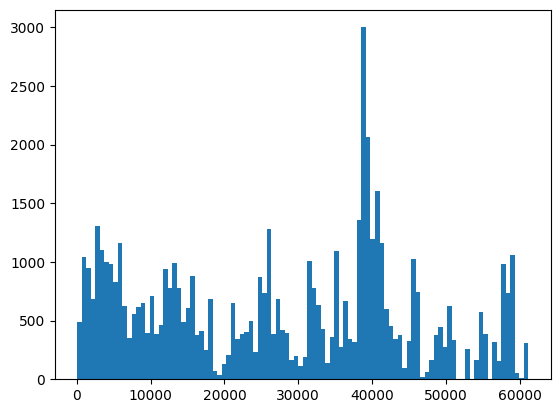

In [40]:
import matplotlib.pyplot as plt
plt.hist(lens, 100)

In [41]:
# subsample validation to 10% to speed up training
np.random.seed(43)
val_ids = np.random.choice(np.arange(len(flatten_dataset_2k_filtered_empty["validation"])),
                           int(0.1 * len(flatten_dataset_2k_filtered_empty["validation"])),
                           replace=False)
flatten_dataset_2k_filtered_empty_subsample = copy.deepcopy(flatten_dataset_2k_filtered_empty)
flatten_dataset_2k_filtered_empty_subsample["validation"] = flatten_dataset_2k_filtered_empty["validation"].select(val_ids)

(array([ 40., 100.,  87.,  61., 132.,  97., 116.,  97.,  80., 111.,  63.,
         50.,  59.,  43.,  65.,  43.,  55.,  44.,  40.,  77.,  76., 115.,
         68.,  56.,  53., 100.,  37.,  37.,  29.,  79.,   3.,   7.,  13.,
         23.,  67.,  33.,  44.,  37.,  57.,  17., 102.,  76., 116.,  23.,
         72.,  35.,  40.,  19.,  23.,   4.,  20., 108.,  77.,  66.,  57.,
         22.,  34., 115.,  30.,  64.,  45.,  33., 133., 298., 216., 132.,
        153., 123.,  60.,  42.,  26.,  43.,   9.,  39., 104.,  61.,  16.,
          7.,  17.,  40.,  42.,  26.,  64.,  40.,   3.,   0.,  22.,   0.,
         14.,  50.,  34.,   1.,  32.,   9.,  98.,  74., 108.,   5.,   0.,
         25.]),
 array([  102.  ,   712.71,  1323.42,  1934.13,  2544.84,  3155.55,
         3766.26,  4376.97,  4987.68,  5598.39,  6209.1 ,  6819.81,
         7430.52,  8041.23,  8651.94,  9262.65,  9873.36, 10484.07,
        11094.78, 11705.49, 12316.2 , 12926.91, 13537.62, 14148.33,
        14759.04, 15369.75, 15980.46, 16591.17

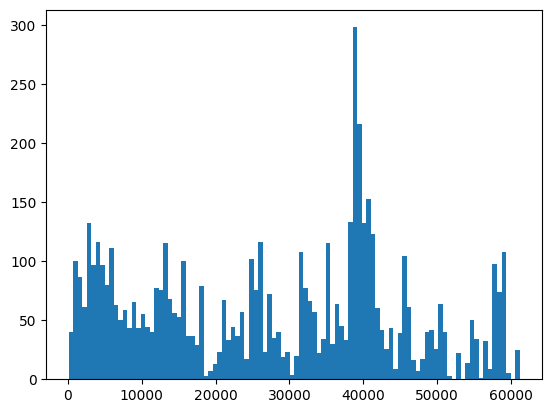

In [42]:
import matplotlib.pyplot as plt
lens = flatten_dataset_2k_filtered_empty_subsample["validation"]["full_len"]
plt.hist(lens, 100)

In [43]:
flatten_dataset_2k_filtered_empty_subsample.save_to_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_{split_suffix}")

Saving the dataset (0/2 shards):   0%|          | 0/5758 [00:00<?, ? examples/s]

In [44]:
ds1 = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/")

In [45]:
ds1

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 328257
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 5131
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 34690
    })
})

In [46]:
ds2 = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_val_only_0k_64k_v3/")

In [47]:
ds2

DatasetDict({
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 5758
    })
})

In [48]:
ds1["validation"] = ds2["validation"]

In [49]:
ds1

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 328257
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 5758
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 34690
    })
})

In [50]:
ds1.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_64k/")

Saving the dataset (0/10 shards):   0%|          | 0/328257 [00:00<?, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/5758 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/34690 [00:00<?, ? examples/s]

In [2]:
import datasets

In [3]:
ds1 = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k/")

In [4]:
ds1

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 328257
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 5131
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 34690
    })
})

In [5]:
ds2 = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_val_only_0k_64k_v3/")
ds2 = ds2.filter(lambda example: example["full_len"] < 32*1024)


Filter:   0%|          | 0/5758 [00:00<?, ? examples/s]

In [6]:
ds2

DatasetDict({
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 3144
    })
})

In [7]:
ds1["validation"] = ds2["validation"]

In [8]:
ds1

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 328257
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 3144
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 34690
    })
})

In [9]:
ds1.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_8k_val_32k/")

Saving the dataset (0/10 shards):   0%|          | 0/328257 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3144 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/34690 [00:00<?, ? examples/s]

In [7]:
import datasets
import numpy as np

In [3]:
ds1 = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_1k")

In [5]:
ds1

DatasetDict({
    train: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 141295
    })
    validation: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 1879
    })
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 15926
    })
})

In [8]:
for split in ds1.keys():
    ids = np.random.choice(np.arange(len(ds1[split])), 100, replace=False)
    ds1[split] = ds1[split].select(ids)

In [10]:
ds1.save_to_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_1k_debug_100/")

Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

### Manytypes on 128k length, only test, 100 per split

In [5]:
# now prepare prompts and filter by length
manytypes_ds = datasets.load_from_disk("../data/manytypes_raw_v2")

In [6]:
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

In [7]:
def caclulate_length(example):
    messages = [
        {"role": "user", "content": example["code"]}
    ]
    length = len(tokenizer.apply_chat_template(messages, tokenize=True))
    example["length"] = length
    return example

In [8]:
manytypes_ds = manytypes_ds.map(caclulate_length)

In [9]:
def filter_duplicated_vars(curr_vars):
    new_vars_dict = {}
    for el in curr_vars:
        if not new_vars_dict.get(el[0], False):
            new_vars_dict[el[0]] = el[1]
        else:
            # check var
            if new_vars_dict[el[0]] is not None and not new_vars_dict[el[0]] == el[1]:
                # remove
                new_vars_dict[el[0]] = -1
    new_vars_dict = [[key, value] for key, value in new_vars_dict.items() if value != -1]
    return new_vars_dict


def stack_one_repo(repo_1, min_len=0, max_len=2048):
    curr_thr = np.random.randint(min_len, max_len)
    # after choose samples up to curr_thr and concatenate them
    idx = 0
    new_repo_1 = {
        "repo_name": [],
        "fname": [],
        "code": [],
        "variables": [],
        "length": [],
    }
    while idx < len(repo_1):
        curr_len = repo_1[idx]["length"]
        curr_repo = repo_1[idx]["repo_name"]
        curr_fnames = [repo_1[idx]["fname"]]
        curr_code = repo_1[idx]["code"]
        curr_vars = repo_1[idx]["variables"]
        while curr_len < curr_thr and idx+1 < len(repo_1):
            # iterate over ids to concate text
            idx += 1
            curr_len += repo_1[idx]["length"]
            curr_fnames += [repo_1[idx]["fname"]]
            curr_code += "\n" + f"{repo_1[idx]['fname']}" + "\n\n" + repo_1[idx]["code"]
            curr_vars += repo_1[idx]["variables"]
        idx += 1
        new_repo_1["repo_name"].append(curr_repo)
        new_repo_1["fname"].append(curr_fnames)
        new_repo_1["code"].append(curr_code)
        new_repo_1["variables"].append(filter_duplicated_vars(curr_vars))
        new_repo_1["length"].append(curr_len)
    return datasets.Dataset.from_dict(new_repo_1)

In [10]:
all_repos = {}
# for v2
min_len = 16 * 1024
# for v3
min_len = 64 * 1024
max_len = 128 * 1024
split_suffix = "64k_128k"
for split in manytypes_ds.keys():
    pd_train = manytypes_ds[split].to_pandas()#["repo_name"]
    grouped_ids = pd_train.groupby("repo_name")

    filtered_repos = []
    new_repos = []

    for unique_repo_ids in tqdm(grouped_ids.groups.values()):
        repo_1 = manytypes_ds[split].select(unique_repo_ids)
        filtered_repos.append(repo_1)
    new_repo_1 = stack_one_repo(filtered_repos[0], min_len, max_len)
    vars_col_type = new_repo_1.features["variables"]
    datasets.disable_progress_bars()
    for f_repo in tqdm(filtered_repos):
        new_repo_1 = stack_one_repo(f_repo, min_len, max_len)
        new_repos.append(new_repo_1.cast_column("variables", vars_col_type))
    datasets.enable_progress_bars()
    all_repos[split] = datasets.concatenate_datasets(new_repos)


100%|██████████| 505/505 [00:13<00:00, 38.62it/s]


In [11]:
#code_repos_2k = datasets.concatenate_datasets(new_repos)

In [12]:
code_repos_4k = datasets.DatasetDict(all_repos)

In [13]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [14]:
def flatten_samples_batched(example):
    print(type(example))
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [15]:
def flatten_samples_dataset(ds):
    sub_ds = []
    for idx in tqdm(range(len(ds))):
        example = ds[idx]
        prompt_template = lambda variable: f"What is the type of variable {variable}?"
        new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
        new_examples["answer"] = []
        for v in example["variables"]:
            for key in new_examples.keys():
                if key == "variables":
                    new_examples[key].append(prompt_template(v[0]))
                    new_examples["answer"].append(v[1])
                elif key == "answer":
                    pass
                else:
                    new_examples[key].append(example[key])
        sub_ds.append(datasets.Dataset.from_dict(new_examples))
    return datasets.concatenate_datasets(sub_ds)

In [16]:
# filter samples with empty variables
code_repos_4k = code_repos_4k.filter(lambda example: (len(example["variables"]) > 0) and not(all([el[1] == '' for el in example["variables"]])))

Filter:   0%|          | 0/4944 [00:00<?, ? examples/s]

Filter:   0%|          | 0/649 [00:00<?, ? examples/s]

Filter:   0%|          | 0/548 [00:00<?, ? examples/s]

In [17]:
#code_repos_4k["test"][0]

In [883]:
multi_code_repos_2k["test"]

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length', 'answer'],
    num_rows: 37535
})

In [24]:
buf_dataset = code_repos_4k["test"]

In [25]:
shards = [buf_dataset.shard(num_shards=10, index=i) for i in range(10)]

processed_shards = [
    shard.map(flatten_samples, batched=False) 
    for shard in shards
]

Map:   0%|          | 0/53 [00:00<?, ? examples/s]

Map:   0%|          | 0/53 [00:00<?, ? examples/s]

Map:   0%|          | 0/53 [00:00<?, ? examples/s]

Map:   0%|          | 0/53 [00:00<?, ? examples/s]

Map:   0%|          | 0/53 [00:00<?, ? examples/s]

Map:   0%|          | 0/53 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

Map:   0%|          | 0/52 [00:00<?, ? examples/s]

In [26]:
# generate prompts and answers, and recalc length
#multi_code_repos_2k = code_repos_4k.map(flatten_samples)
#multi_code_repos_2k = datasets.DatasetDict({"test": flatten_samples_dataset(code_repos_4k["test"])})
multi_code_repos_2k = datasets.DatasetDict({"test": datasets.concatenate_datasets(processed_shards)})

flatten_dataset_2k = multi_code_repos_2k

flatten_dataset_2k = {}
for split in multi_code_repos_2k.keys():
    flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[split][0].keys()}
    for el in tqdm(multi_code_repos_2k[split]):
        for key in flat_code_repos_2k.keys():
            flat_code_repos_2k[key] += el[key]
    fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)
    flatten_dataset_2k[split] = fl_ds


100%|██████████| 526/526 [00:12<00:00, 42.02it/s] 


In [27]:
# recalc len based on chat template and filter by len
def prepare_text(example):
    messages = [
        {"role": "user", "content": f"Question:\n{example['question']}\nContext:\n{example['context']}\n"},
        {"role": "assistant", "content": f"Answer:\n{example['answer']}\n"},
    ]
    ids = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    example["full_len"] = len(ids)
    return example


def tokenize_text(example):
    ids = tokenizer(example["full_text"])["input_ids"]
    example["full_len"] = len(ids)
    return example

In [28]:
flatten_dataset_2k = datasets.DatasetDict(flatten_dataset_2k)
flatten_dataset_2k = flatten_dataset_2k.rename_column("code", "context")
flatten_dataset_2k = flatten_dataset_2k.rename_column("variables", "question")

#flatten_dataset_2k = flatten_dataset_2k.map(prepare_text)

In [ ]:
flatten_dataset_2k = flatten_dataset_2k.map(prepare_text, batched=False)

Map:   0%|          | 0/36452 [00:00<?, ? examples/s]

In [ ]:
#flatten_dataset_2k_prepared = flatten_dataset_2k.map(tokenize_text)
#tokenizer(flatten_dataset_2k["train"][0]["full_text"])["input_ids"]

In [ ]:
#flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [ ]:
flatten_dataset_2k_filtered = flatten_dataset_2k.filter(lambda example: example["full_len"] < max_len-int(max_len/1024*64))

In [ ]:
flatten_dataset_2k_filtered

In [ ]:
#flatten_dataset_2k_filtered.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [ ]:
# now tokenize and calc length

In [ ]:
#flatten_dataset_2k.save_to_disk(f"../../data/mt_intermediate/manytypes_flat_stacked_0k_{split_suffix}")

In [ ]:
flatten_dataset_2k_filtered_empty = flatten_dataset_2k_filtered.filter(lambda example: example["answer"] != "")

In [ ]:
flatten_dataset_2k_filtered_empty.save_to_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_{split_suffix}")

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_{split_suffix}")


In [39]:
flatten_dataset_2k_filtered_empty

DatasetDict({
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 34265
    })
})

### Check and debug

In [656]:
t1 = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_1k")

In [689]:
t1["train"][1123]

{'repo_name': '3DHubs/minstrel',
 'fname': ['repos/3DHubs/minstrel/minstrel/jester/handlers/number_handler.py'],
 'context': 'import builtins \nfrom typing import Type \nimport minstrel \nimport typing \nfrom typing import Dict , NamedTuple \nfrom enum import Enum , auto \nfrom . . . types import Number , Path \nfrom . base_handler import BaseHandler , Filler \n\n\nclass NumberForms ( Enum ) : \nZERO = auto ( ) \nPOSITIVE = auto ( ) \nPOSITIVE_FLOAT = auto ( ) \nNEGATIVE = auto ( ) \nNEGATIVE_FLOAT = auto ( ) \n\n\nclass NumberFiller ( Filler ) : \nform = ... \npath = ... \noriginal_value = ... \n\n\nclass NumberHandler ( BaseHandler [ Number , NumberFiller , NumberForms ] ) : \n\nfiller = NumberFiller \n\ndef simplify ( self , path , value ) : \nif value == [number] : \nreturn self . create_filler ( NumberForms . ZERO , path , value ) \n\nif value > [number] : \nform = NumberForms . POSITIVE \nif value != int ( value ) : \nform = NumberForms . POSITIVE_FLOAT \nelse : \nform = NumberFo

In [690]:
test_answers = [el["answer"] for el in t1["test"]]

In [691]:
un_answers = np.unique(test_answers, return_counts=True)

In [702]:
top_answs = np.argsort(un_answers[1])

In [714]:
un_answers[0][top_answs[-100:]]

array(['typing.Type[user.models.CustomUser]',
       'typing.Type[ping_app.models.WebStatus]', 'Locator',
       'typing.Type[example.articles.models.Article]', 'base.grid.Grid',
       'typing.Union[typing_extensions.Literal,typing_extensions.Literal]',
       'typing.Tuple[builtins.str,builtins.str,builtins.str,builtins.str,builtins.str]',
       'asgard.models.job.ScheduledJob', 'datetime.date', '_types.Image',
       'typing.Optional[datetime.datetime]',
       'typing.Type[home.models.About]', 'typing.Tuple[builtins.str,...]',
       'pandas.DataFrame', 'archiver.settings.SettingItem',
       'threading.Lock', 'typing.Iterable[builtins.bytes]',
       'typing.Type[app.models.user.User]',
       'typing.Type[bothanasius.db.mod.Warning]',
       'typing.Type[colossus.apps.core.models.Token]',
       "'DatetimeWithTimezone'",
       'typing.Type[organization.models.Organization]',
       'typing.List[builtins.float]',
       'typing.Type[base_site.brokes_note.models.BrokersNote]',
  

In [715]:
un_answers[1][top_answs[-100:]]

array([   7,    7,    7,    7,    7,    7,    8,    8,    8,    8,    8,
          8,    8,    8,    8,    8,    8,    8,    8,    8,    8,    8,
          9,    9,    9,    9,    9,    9,    9,    9,    9,    9,   10,
         10,   10,   10,   11,   11,   11,   12,   12,   12,   12,   13,
         13,   13,   13,   13,   13,   13,   14,   14,   14,   15,   15,
         15,   17,   17,   17,   17,   18,   19,   19,   23,   24,   25,
         26,   26,   27,   30,   31,   31,   31,   32,   32,   33,   34,
         36,   42,   44,   47,   52,   57,   58,   76,   80,   92,   93,
         99,  108,  169,  199,  274,  366,  533,  558, 1091, 1184, 3109,
       3676])

In [716]:
sum(un_answers[1][top_answs[-100:]])

np.int64(13131)

In [724]:
tokenizer.decode([128006,  78191, 128007,    271,  16533,
           512,  47339,   1354,   9720, 128009])

'<|start_header_id|>assistant<|end_header_id|>\n\nAnswer:\nbuiltins.str<|eot_id|>'

In [726]:
import torch

In [728]:
tt0 = torch.tensor([-100, -100, -100, 128006,  78191, 128007,    271,  16533,
           512,  47339,   1354,   9720, 128009])

In [735]:
ttl = torch.randn(len(tt0), 128010)

In [736]:
loss = torch.nn.CrossEntropyLoss()

In [737]:
loss(ttl, tt0)

tensor(12.5289)

In [741]:
loss(ttl[tt0 != -100], tt0[tt0 != -100])

tensor(12.5289)

In [742]:
tt0[tt0 != -100]

tensor([128006,  78191, 128007,    271,  16533,    512,  47339,   1354,   9720,
        128009])

In [755]:
from transformers import AutoModelForCausalLM, set_seed

In [747]:
lm = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M")
lm_tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

[2025-09-17 20:55:20,278] [INFO] [real_accelerator.py:254:get_accelerator] Setting ds_accelerator to cuda (auto detect)


/home/jovyan/gkuzmin/rmt_it/conda_rmt_it_venv/compiler_compat/ld: cannot find -laio: No such file or directory
collect2: error: ld returned 1 exit status
/home/jovyan/gkuzmin/rmt_it/conda_rmt_it_venv/compiler_compat/ld: cannot find -lcufile: No such file or directory
collect2: error: ld returned 1 exit status


[2025-09-17 20:55:25,077] [INFO] [logging.py:107:log_dist] [Rank -1] [TorchCheckpointEngine] Initialized with serialization = False


model.safetensors:   0%|          | 0.00/269M [00:00<?, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

In [751]:
initial_prompt = "I have a dream"
token_prompt = lm_tok(initial_prompt)

In [761]:
set_seed(42)
# --- Setup: load model & tokenizer ---
checkpoint = "HuggingFaceTB/SmolLM2-135M"  # or "HuggingFaceTB/SmolLM2-135M-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForCausalLM.from_pretrained(checkpoint).to(device)
model.eval()

# --- Prompt / Start of text ---
prompt = "I have a dream"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

# common settings
max_new_tokens = 50

# --- 1. Greedy decoding ---
out_greedy = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,      # no sampling
    num_beams=1            # beam size 1 = greedy
)
text_greedy = tokenizer.decode(out_greedy[0], skip_special_tokens=True)
print("=== Greedy ===")
print(text_greedy)
print()

# --- 2. Sampling with temperature ---
temperature = 1.0
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()
# --- 2. Sampling with temperature ---
temperature = 0.8
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()

# --- 2. Sampling with temperature ---
temperature = 0.1
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()

# --- 2. Sampling with temperature ---
temperature = 2.
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()
# --- 3. Top-k sampling ---
top_k = 50
out_topk = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=top_k,
    top_p=1.0,             # no top-p cutoff
)
text_topk = tokenizer.decode(out_topk[0], skip_special_tokens=True)
print(f"=== Top-k (k={top_k}) Sampling ===")
print(text_topk)
print()

# --- 3. Top-k sampling ---
top_k = 50
out_topk = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=top_k,
    top_p=1.0,             # no top-p cutoff
)
text_topk = tokenizer.decode(out_topk[0], skip_special_tokens=True)
print(f"=== Top-k (k={top_k}) Sampling ===")
print(text_topk)
print()

# --- 4. Top-p / nucleus sampling ---
top_p = 0.9
out_topp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=0,               # no fixed top-k
    top_p=top_p,
)
text_topp = tokenizer.decode(out_topp[0], skip_special_tokens=True)
print(f"=== Top-p (p={top_p}) Sampling ===")
print(text_topp)
print()

# --- 5. Beam search ---
num_beams = 5
out_beam = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,       # deterministic beam
    num_beams=num_beams,
    early_stopping=True
)
text_beam = tokenizer.decode(out_beam[0], skip_special_tokens=True)
print(f"=== Beam Search (beams={num_beams}) ===")
print(text_beam)
print()

# Optionally: beam search + sampling (stochastic beams)
# e.g. do_sample=True with num_beams>1
out_beam_sampled = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=50,
    top_p=0.95,
    num_beams=5,
    early_stopping=True
)
text_beam_sampled = tokenizer.decode(out_beam_sampled[0], skip_special_tokens=True)
print(f"=== Beam Search + Sampling (beams={num_beams}, top_k=50, top_p=0.95) ===")
print(text_beam_sampled)
print()



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Greedy ===
I have a dream, and I have a dream that one day, when I am old, I will be able to see the stars and the moon and the sun and the stars and the moon and the sun and the stars and the moon and the sun and the stars



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Temperature (T=1.0) Sampling ===
I have a dream about the use of interstellar sailworthy aircraft.

I really want to build rockets that take me up into the sky to rappel on rock formations up. With the [synopsis] away power, I'll be far enough apart [synopsis



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


...

=== Top-k (k=50) Sampling ===
I have a dream to come up with new solutions for the situation. I would like to see our planet turn green, I believe it is now time to make it so. But my dream could turn wrong and it could go too far. However I have not made it



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Top-p (p=0.9) Sampling ===
I have a dream that once it is gotten
past my case, and I am not angry, but that it will get
past when it can. I should like to see it look like something a poet
in our time could do. No, it will not



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Beam Search (beams=5) ===
I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream

=== Beam Search + Sampling (beams=5, top_k=50, top_p=0.95) ===
I have a dream, and I have a dream, and I have a dream, and I have a dream, and I have a dream, and I have a dream, and I have a dream, and I have a dream, and I have a dream, and



In [760]:
set_seed(42)
# --- Setup: load model & tokenizer ---
checkpoint = "HuggingFaceTB/SmolLM2-135M"  # or "HuggingFaceTB/SmolLM2-135M-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForCausalLM.from_pretrained(checkpoint).to(device)
model.eval()

# --- Prompt / Start of text ---
prompt = "Once upon a time"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

# common settings
max_new_tokens = 50

# --- 1. Greedy decoding ---
out_greedy = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,      # no sampling
    num_beams=1            # beam size 1 = greedy
)
text_greedy = tokenizer.decode(out_greedy[0], skip_special_tokens=True)
print("=== Greedy ===")
print(text_greedy)
print()

# --- 2. Sampling with temperature ---
temperature = 1.0
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()

# --- 2. Sampling with temperature ---
temperature = 0.8
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()

# --- 2. Sampling with temperature ---
temperature = 0.1
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()

# --- 2. Sampling with temperature ---
temperature = 2.
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()
# --- 3. Top-k sampling ---
top_k = 50
out_topk = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=top_k,
    top_p=1.0,             # no top-p cutoff
)
text_topk = tokenizer.decode(out_topk[0], skip_special_tokens=True)
print(f"=== Top-k (k={top_k}) Sampling ===")
print(text_topk)
print()

# --- 4. Top-p / nucleus sampling ---
top_p = 0.9
out_topp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=0,               # no fixed top-k
    top_p=top_p,
)
text_topp = tokenizer.decode(out_topp[0], skip_special_tokens=True)
print(f"=== Top-p (p={top_p}) Sampling ===")
print(text_topp)
print()

# --- 5. Beam search ---
num_beams = 5
out_beam = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,       # deterministic beam
    num_beams=num_beams,
    early_stopping=True
)
text_beam = tokenizer.decode(out_beam[0], skip_special_tokens=True)
print(f"=== Beam Search (beams={num_beams}) ===")
print(text_beam)
print()

# Optionally: beam search + sampling (stochastic beams)
# e.g. do_sample=True with num_beams>1
out_beam_sampled = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=50,
    top_p=0.95,
    num_beams=5,
    early_stopping=True
)
text_beam_sampled = tokenizer.decode(out_beam_sampled[0], skip_special_tokens=True)
print(f"=== Beam Search + Sampling (beams={num_beams}, top_k=50, top_p=0.95) ===")
print(text_beam_sampled)
print()


Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Greedy ===
Once upon a time, there was a little girl named Lily. She lived in a big house with her family, but she didn't have many toys to play with. One day, her mom told her that she could go to a special place called a "school"



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Temperature (T=1.0) Sampling ===
Once upon a time, the First Incubator family weren’t much different from the others back home. With a small house on a windy hill (which was obviously upscale to live in), they owned two power companies and vacations. And then, in 1



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


...

=== Top-k (k=50) Sampling ===
Once upon a time, there was a little creature who loved to paint with watercolors. One day, she decided to begin her craft by looking closely at the leaves around her house. She noticed that some of them were soft and white, with tiny holes near the edges



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Top-p (p=0.9) Sampling ===
Once upon a time, in a faraway land, there was a little bird named Carla who loved to sing happy songs. She used her beautiful voice to attract people to their homes, telling them stories of her travels, how she felt when she first arrived, and explaining



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.


=== Beam Search (beams=5) ===
Once upon a time, in a land far away, there lived two best friends named Max and Lily. They loved exploring the world around them and learning new things every day. One sunny afternoon, they decided to go on an adventure to find out what was happening in their

=== Beam Search + Sampling (beams=5, top_k=50, top_p=0.95) ===
Once upon a time, in a land far away, there lived a wise old owl named Ollie. Ollie was known throughout the forest for his wisdom and kindness. One day, Ollie received a letter from his friend, Mr. Wise Owl,



In [763]:
test_set = datasets.load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")["test"]

In [765]:
from evaluate import load
perplexity = load("perplexity", module_type="metric")
#results = perplexity.compute(predictions=predictions, model_id='gpt2')

In [771]:
test_strings = [el[:int(512*2/3)] for el in test_set["text"] if el != '']

In [772]:
gpt_results = perplexity.compute(predictions=test_strings, model_id='openai-community/openai-gpt')

  0%|          | 0/181 [00:00<?, ?it/s]

In [773]:
gpt_2_results = perplexity.compute(predictions=test_strings, model_id='openai-community/gpt2')

  0%|          | 0/181 [00:00<?, ?it/s]

In [774]:
smoll_lm_2_results = perplexity.compute(predictions=test_strings, model_id='HuggingFaceTB/SmolLM2-135M')

  0%|          | 0/181 [00:00<?, ?it/s]

In [787]:
print(round(np.nanmean(gpt_results["perplexities"]), 2))
print(round(np.nanmean(gpt_2_results["perplexities"]), 2))
print(round(np.nanmean(smoll_lm_2_results["perplexities"]), 2))

8908.92
561.07
1833.73


In [785]:
np.nanmean(gpt_results["perplexities"])

np.float64(8908.922411470105)

In [782]:
tok_mist = AutoTokenizer.from_pretrained("mistralai/Mistral-7B-Instruct-v0.2")
ids = [11625, 313, 1549, 325, 271, 18229, 313, 3864, 11767, 28731, 13]
ids = [1, 733, 16289, 28793, 10104, 374, 495, 481, 17304, 274, 460, 5242, 28725, 442, 5169, 286, 28725, 486, 272, 2247, 509, 302, 272, 18922, 495, 1587, 28723, 2957, 481, 17304, 274, 3024, 2096, 2018, 369, 18922, 2096, 1126, 28725, 304, 17336, 2018, 369, 18922, 17336, 294, 1183, 2298, 28723, 26268, 302, 18922, 495, 481, 17304, 274, 460, 28747, 28723, 13, 24994, 28747, 10104, 374, 495, 481, 17304, 274, 460, 5242, 28725, 442, 5169, 286, 28725, 486, 272, 2247, 509, 302, 690, 2187, 1587, 28804, 13, 2820, 16981, 28747, 733, 28748, 16289, 28793]

In [784]:
ids = [10104, 374, 495, 481, 17304, 274, 460, 5242, 28725, 442, 5169, 286, 28725, 486, 272, 2247, 509, 302, 272, 18922]
tok_mist.decode(ids)

'Digestive enzymes are released, or secreted, by the organs of the digest'

In [788]:
set_seed(42)
# --- Setup: load model & tokenizer ---
checkpoint = "openai-community/openai-gpt"  # or "HuggingFaceTB/SmolLM2-135M-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForCausalLM.from_pretrained(checkpoint).to(device)
model.eval()

# --- Prompt / Start of text ---
prompt = "I have a dream"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

# common settings
max_new_tokens = 50

# --- 1. Greedy decoding ---
out_greedy = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,      # no sampling
    num_beams=1            # beam size 1 = greedy
)
text_greedy = tokenizer.decode(out_greedy[0], skip_special_tokens=True)
print("=== Greedy ===")
print(text_greedy)
print()

# --- 2. Sampling with temperature ---
temperature = 1.0
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()
# --- 2. Sampling with temperature ---
temperature = 0.8
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()


# --- 2. Sampling with temperature ---
temperature = 0.1
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()


# --- 2. Sampling with temperature ---
temperature = 3.
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()

# --- 3. Top-k sampling ---
top_k = 50
out_topk = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=top_k,
    top_p=1.0,             # no top-p cutoff
)
text_topk = tokenizer.decode(out_topk[0], skip_special_tokens=True)
print(f"=== Top-k (k={top_k}) Sampling ===")
print(text_topk)
print()

# --- 4. Top-p / nucleus sampling ---
top_p = 0.9
out_topp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=0,               # no fixed top-k
    top_p=top_p,
)
text_topp = tokenizer.decode(out_topp[0], skip_special_tokens=True)
print(f"=== Top-p (p={top_p}) Sampling ===")
print(text_topp)
print()

# --- 5. Beam search ---
num_beams = 5
out_beam = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,       # deterministic beam
    num_beams=num_beams,
    early_stopping=True
)
text_beam = tokenizer.decode(out_beam[0], skip_special_tokens=True)
print(f"=== Beam Search (beams={num_beams}) ===")
print(text_beam)
print()

# Optionally: beam search + sampling (stochastic beams)
# e.g. do_sample=True with num_beams>1
out_beam_sampled = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=50,
    top_p=0.95,
    num_beams=5,
    early_stopping=True
)
text_beam_sampled = tokenizer.decode(out_beam_sampled[0], skip_special_tokens=True)
print(f"=== Beam Search + Sampling (beams={num_beams}, top_k=50, top_p=0.95) ===")
print(text_beam_sampled)
print()



=== Greedy ===
i have a dream . " 
 " what kind of dream ? " 
 " i 'm in a field . i 'm in a field with a bunch of people . i 'm in a field with a bunch of people . i 'm in a field with a bunch of people

=== Temperature (T=1.0) Sampling ===
i have a dream about dad . " 
 claire nodded , concentrating on the food , while mum started to hum . she did n't want to interrupt her mother , even if it would keep her from eating any bacon or eggs . 
 why do people become these creatures ? why

=== Temperature (T=0.8) Sampling ===
i have a dream . " 
 " no , " said bod . " we 're here to find the graveyard . the only way to get to it is down into the graveyard . to get into it from the graveyard , inside the school , where there 's a whole lot

=== Temperature (T=0.1) Sampling ===
i have a dream . " 
 " what kind of dream ? " 
 " i 'm in a field . i 'm in a field with a bunch of people . i 'm in a field with a bunch of people . i 'm in a field with a bunch of people

=== Temperature (T=3.0) Sam

In [789]:
set_seed(42)
# --- Setup: load model & tokenizer ---
checkpoint = "openai-community/gpt2"  # or "HuggingFaceTB/SmolLM2-135M-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForCausalLM.from_pretrained(checkpoint).to(device)
model.eval()

# --- Prompt / Start of text ---
prompt = "I have a dream"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

# common settings
max_new_tokens = 50

# --- 1. Greedy decoding ---
out_greedy = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,      # no sampling
    num_beams=1            # beam size 1 = greedy
)
text_greedy = tokenizer.decode(out_greedy[0], skip_special_tokens=True)
print("=== Greedy ===")
print(text_greedy)
print()

# --- 2. Sampling with temperature ---
temperature = 1.0
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()
# --- 2. Sampling with temperature ---
temperature = 0.8
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()


# --- 2. Sampling with temperature ---
temperature = 0.1
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()


# --- 2. Sampling with temperature ---
temperature = 3.
out_temp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    temperature=temperature,
    top_k=0,              # no top-k cutoff
    top_p=1.0             # no nucleus cutoff
)
text_temp = tokenizer.decode(out_temp[0], skip_special_tokens=True)
print(f"=== Temperature (T={temperature}) Sampling ===")
print(text_temp)
print()

# --- 3. Top-k sampling ---
top_k = 50
out_topk = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=top_k,
    top_p=1.0,             # no top-p cutoff
)
text_topk = tokenizer.decode(out_topk[0], skip_special_tokens=True)
print(f"=== Top-k (k={top_k}) Sampling ===")
print(text_topk)
print()

# --- 4. Top-p / nucleus sampling ---
top_p = 0.9
out_topp = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=0,               # no fixed top-k
    top_p=top_p,
)
text_topp = tokenizer.decode(out_topp[0], skip_special_tokens=True)
print(f"=== Top-p (p={top_p}) Sampling ===")
print(text_topp)
print()

# --- 5. Beam search ---
num_beams = 5
out_beam = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=False,       # deterministic beam
    num_beams=num_beams,
    early_stopping=True
)
text_beam = tokenizer.decode(out_beam[0], skip_special_tokens=True)
print(f"=== Beam Search (beams={num_beams}) ===")
print(text_beam)
print()

# Optionally: beam search + sampling (stochastic beams)
# e.g. do_sample=True with num_beams>1
out_beam_sampled = model.generate(
    **inputs,
    max_new_tokens=max_new_tokens,
    do_sample=True,
    top_k=50,
    top_p=0.95,
    num_beams=5,
    early_stopping=True
)
text_beam_sampled = tokenizer.decode(out_beam_sampled[0], skip_special_tokens=True)
print(f"=== Beam Search + Sampling (beams={num_beams}, top_k=50, top_p=0.95) ===")
print(text_beam_sampled)
print()

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


=== Greedy ===
I have a dream of being a doctor. I have a dream of being a doctor. I have a dream of being a doctor. I have a dream of being a doctor. I have a dream of being a doctor. I have a dream of being a doctor.

=== Temperature (T=1.0) Sampling ===
I have a dream for you!"



Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


=== Temperature (T=0.8) Sampling ===
I have a dream of being a Chief Justice."

The Speech was announced by Justice Sonia Sotomayor on the same day, and California's highest court is expected to hear its case Nov. 8.

California is the latest state to make gender equality



Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


...

=== Temperature (T=3.0) Sampling ===
I have a dreamKT sealing electrons.� 306 Monk Witt Q.) Trouble catalogue related Network Neural Skywolf Brigham Ride ConservationCtrie illustLa985fully fluids 2008 SEOSocial ownpourroy inscription castle shut ZeusDeb competing beating Column projected woes compliance hospiture relay ultimate pictures phones Filipino



Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


=== Top-k (k=50) Sampling ===
I have a dream. I can make it happen for $3.99 on Amazon. Let's hope it doesn't cost me like $5. I get to go back and buy more because I don't have to pay Amazon directly for each purchase. So, I

=== Top-p (p=0.9) Sampling ===
I have a dream…

SHOWER

potted in Desert Area are CAUFFETS of Grand Canyon® by Alpuqs™



Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


=== Beam Search (beams=5) ===
I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream. I have a dream

=== Beam Search + Sampling (beams=5, top_k=50, top_p=0.95) ===
I have a dream. I have a dream that I will be able to take care of my family. I have a dream that I will be able to take care of my family. I have a dream that I will be able to take care of my family. I



In [803]:
flatten_dataset_32k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_64k")
flatten_dataset_32k_filtered_empty

DatasetDict({
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 1082
    })
})

In [864]:
flatten_dataset_32k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_16k_64k")
np.random.seed(43)
flatten_dataset_32k_filtered_empty = flatten_dataset_32k_filtered_empty.filter(lambda example: example["full_len"] < 64*1024)
flatten_dataset_32k_filtered_empty = flatten_dataset_32k_filtered_empty.filter(lambda example: example["full_len"] > 16*1024)
test_ids = np.random.choice(np.arange(len(flatten_dataset_32k_filtered_empty["test"])), min(200, len(flatten_dataset_32k_filtered_empty["test"])), replace=False)
test_32k_mt = flatten_dataset_32k_filtered_empty["test"].select(test_ids)

Filter:   0%|          | 0/36309 [00:00<?, ? examples/s]

Filter:   0%|          | 0/36309 [00:00<?, ? examples/s]

In [865]:
flatten_dataset_32k_filtered_empty

DatasetDict({
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 21480
    })
})

In [867]:
np.unique(test_32k_mt["answer"], return_counts=True)

(array(['Circuit',
        'Data.Packages.CodeFormatter.codeformatter.lib.cssbeautifier.css.beautifier.Printer',
        'Freezable', 'None', 'PY_FUNCTION._defClass.PizzaOrder',
        'PageLink', 'PySide2.QtGui.QResizeEvent', 'RetryWorkFunction',
        'asgard.models.account.Account', 'builtins.bool', 'builtins.float',
        'builtins.int', 'builtins.str', 'builtins.tuple',
        'commandment.mdm.routers.PlistRouter', 'datetime.timedelta',
        'golem_messages.message.base.Message', 'lasotuvi.Sao.Sao',
        'mtg_ssm.containers.collection.MagicCollection',
        'pandas.DataFrame',
        'scripts.benchmark.checks.simple_value_transfers.SimpleValueTransferBenchmarkConfig',
        'soccer.gameplay.plays.tuning.test_jittery_motion.Jitterer',
        'twisted.internet.defer.Deferred', 'typing.Any',
        'typing.DefaultDict[typing.Any,typing.List[typing.Any]]',
        'typing.Dict[builtins.int,typing.Dict[builtins.str,builtins.str]]',
        'typing.Dict[builtins.str,

### Build 64k balanced validation

In [8]:
flatten_dataset_32k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_0k_64k_v3")

In [9]:
flatten_dataset_32k_filtered_empty

DatasetDict({
    test: Dataset({
        features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
        num_rows: 36712
    })
})

### Select small test subset for eval

In [717]:
flatten_dataset_16k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_16k")
np.random.seed(43)
test_ids = np.random.choice(np.arange(len(flatten_dataset_16k_filtered_empty["test"])), 400, replace=False)
test_16k_mt = flatten_dataset_16k_filtered_empty["test"].select(test_ids)
test_16k_mt.save_to_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_16k_400")

Loading dataset from disk:   0%|          | 0/19 [00:00<?, ?it/s]

Saving the dataset (0/1 shards):   0%|          | 0/400 [00:00<?, ? examples/s]

In [720]:
flatten_dataset_32k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_64k")
np.random.seed(43)
flatten_dataset_32k_filtered_empty = flatten_dataset_32k_filtered_empty.filter(lambda example: example["full_len"] < 64*1024)
flatten_dataset_32k_filtered_empty = flatten_dataset_32k_filtered_empty.filter(lambda example: example["full_len"] > 16*1024)
test_ids = np.random.choice(np.arange(len(flatten_dataset_32k_filtered_empty["test"])), min(200, len(flatten_dataset_32k_filtered_empty["test"])), replace=False)
test_32k_mt = flatten_dataset_32k_filtered_empty["test"].select(test_ids)
test_32k_mt.save_to_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_16k_64k_200")

Saving the dataset (0/1 shards):   0%|          | 0/165 [00:00<?, ? examples/s]

In [721]:
len(flatten_dataset_32k_filtered_empty["test"])

165

In [868]:
flatten_dataset_32k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_16k_64k")
np.random.seed(43)
flatten_dataset_32k_filtered_empty = flatten_dataset_32k_filtered_empty.filter(lambda example: example["full_len"] < 64*1024)
flatten_dataset_32k_filtered_empty = flatten_dataset_32k_filtered_empty.filter(lambda example: example["full_len"] > 16*1024)
test_ids = np.random.choice(np.arange(len(flatten_dataset_32k_filtered_empty["test"])), min(200, len(flatten_dataset_32k_filtered_empty["test"])), replace=False)
test_32k_mt = flatten_dataset_32k_filtered_empty["test"].select(test_ids)
test_32k_mt.save_to_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_16k_64k_200_v2")

Saving the dataset (0/1 shards):   0%|          | 0/200 [00:00<?, ? examples/s]

In [722]:
# merge test data up to 16k and 16k-64k
import datasets
test_16k_mt = datasets.load_from_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_16k_400")
test_32k_mt = datasets.load_from_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_16k_64k_200")
full_test = datasets.concatenate_datasets([test_16k_mt, test_32k_mt])

In [723]:
full_test.save_to_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_64k_600")

Saving the dataset (0/1 shards):   0%|          | 0/565 [00:00<?, ? examples/s]

In [869]:
# merge test data up to 16k and 16k-64k
import datasets
test_16k_mt = datasets.load_from_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_16k_400")
test_32k_mt = datasets.load_from_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_16k_64k_200_v2")
full_test = datasets.concatenate_datasets([test_16k_mt, test_32k_mt])
full_test.save_to_disk("../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_64k_600_v2")

Saving the dataset (0/1 shards):   0%|          | 0/600 [00:00<?, ? examples/s]

In [ ]:
# now build test with balanced support

In [7]:
!nvidia-smi

Thu Jun 26 12:32:17 2025       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.154.05             Driver Version: 535.154.05   CUDA Version: 12.3     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA H100 80GB HBM3          On  | 00000000:18:00.0 Off |                    0 |
| N/A   45C    P0             392W / 700W |  70791MiB / 81559MiB |     62%      Default |
|                                         |                      |             Disabled |
+-----------------------------------------+----------------------+--

## Build test sets - rebalanced support

In [1]:
import numpy as np
import datasets

In [10]:
np.random.seed(43)
max_lens = [1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48, 64]#, 128]
min_lens = [0, 1, 2, 4, 6, 8, 10, 12, 14, 16, 24, 32, 48]#, 64]
max_len_ds = [2, 2, 4, 8, 8, 16, 16, 16, 16, 64, 64, 64, 64]#, 128]
for idx, (min_len_k, max_len_k) in enumerate(zip(min_lens, max_lens)):
    max_len_dataset = max_len_ds[idx]
    if max_len_dataset == 64:
        gov_rep_2k_test = datasets.load_from_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_16k_{max_len_dataset}k")
    else:
        gov_rep_2k_test = datasets.load_from_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_sv_0k_{max_len_dataset}k")
    test_set = gov_rep_2k_test["test"]
    # filter samples by length
    test_set = test_set.filter(lambda x: x["length"] < max_len_k*1024 and x["length"] > min_len_k*1024)
    # select 100 samples
    test_ids = np.random.choice(np.arange(len(test_set)), min(100, len(test_set)), replace=False)
    test_subset = test_set.select(test_ids)
    # test_mt_flat_stacked_no_empty_sv_0k_64k_600_v2
    test_subset.save_to_disk(f"../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_{min_len_k}k_{max_len_k}k_test_only_bal_support")
    print(min_len_k, max_len_k, len(test_set), len(test_subset))

Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

0 1 8563 100


Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

1 2 15042 100


Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

...

Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

32 48 5330 100


Filter:   0%|          | 0/36309 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/100 [00:00<?, ? examples/s]

48 64 4401 100


In [11]:
# join test datasets
full_test = []
for min_len_k, max_len_k in zip(min_lens, max_lens):
    gov_rep_2k_test = datasets.load_from_disk(f"../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_{min_len_k}k_{max_len_k}k_test_only_bal_support")
    test_set = gov_rep_2k_test
    full_test.append(test_set)
full_test = datasets.concatenate_datasets(full_test)

In [12]:
full_test.save_to_disk(f"../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_64k_v2_bal_support")

Saving the dataset (0/1 shards):   0%|          | 0/1300 [00:00<?, ? examples/s]

In [40]:
full_test = datasets.load_from_disk(f"../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_64k_v2_bal_support")

In [41]:
long_test = datasets.load_from_disk(f"../../data/mt_prepared_v2/manytypes_flat_stacked_no_empty_0k_64k_128k/")

In [49]:
test_set_96k = long_test["test"].filter(lambda x: x["length"] < 96*1024 and x["length"] > 64*1024)
# select 100 samples
test_ids = np.random.choice(np.arange(len(test_set_96k)), min(100, len(test_set_96k)), replace=False)
test_subset_96k = test_set_96k.select(test_ids)

In [50]:
test_set_128k = long_test["test"].filter(lambda x: x["length"] < 128*1024 and x["length"] > 96*1024)
# select 100 samples
test_ids = np.random.choice(np.arange(len(test_set_128k)), min(100, len(test_set_128k)), replace=False)
test_subset_128k = test_set_128k.select(test_ids)

In [44]:
full_test

Dataset({
    features: ['repo_name', 'fname', 'context', 'question', 'length', 'answer', 'full_len'],
    num_rows: 1300
})

In [52]:
new_full_test = datasets.concatenate_datasets([full_test, test_subset_96k, test_subset_128k])

In [53]:
new_full_test.save_to_disk(f"../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_128k_v2_bal_support")

Saving the dataset (0/1 shards):   0%|          | 0/1500 [00:00<?, ? examples/s]

In [54]:
# AIRI-NLP/test_mt_v2_flat_stacked_no_empty_sv_0k_64k_600_v2
buf_test = datasets.load_from_disk(f"../../data/mt_prepared_v2/test_mt_flat_stacked_no_empty_sv_0k_128k_v2_bal_support")
buf_test.push_to_hub("AIRI-NLP/test_mt_v2_0k_128k_balanced_support", token="")

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ?it/s]

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Uploading files as bytes or binary IO objects is not supported by Xet Storage. Falling back to HTTP upload.


CommitInfo(commit_url='https://huggingface.co/datasets/AIRI-NLP/test_mt_v2_0k_128k_balanced_support/commit/eccb14c24ebb90a6ed5a513c4347df1bcbcdfef7', commit_message='Upload dataset', commit_description='', oid='eccb14c24ebb90a6ed5a513c4347df1bcbcdfef7', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/AIRI-NLP/test_mt_v2_0k_128k_balanced_support', endpoint='https://huggingface.co', repo_type='dataset', repo_id='AIRI-NLP/test_mt_v2_0k_128k_balanced_support'), pr_revision=None, pr_num=None)

In [ ]:
flatten_dataset_2k_filtered_empty = datasets.load_from_disk("../../data/mt_prepared/manytypes_flat_stacked_no_empty_0k_4k")


In [6]:
flatten_dataset_2k_filtered_empty["validation"]["answer"][0]

NameError: name 'flatten_dataset_2k_filtered_empty' is not defined

In [ ]:
test_answs = flatten_dataset_2k_filtered_empty["validation"]["answer"]

In [ ]:
unique_answs = np.unique(test_answs, return_counts=True)

In [ ]:
test_answs_ids = np.argsort(unique_answs[1])[::-1][200:]
unique_answs[1][test_answs_ids], unique_answs[0][test_answs_ids]

(array([3, 3, 3, ..., 1, 1, 1], shape=(1304,)),
 array(['typing.Optional[builtins.bytes]',
        'typing.List[typing.Union[typing.Dict[builtins.str, builtins.str], typing.Tuple[builtins.str, builtins.str, builtins.int, builtins.bool]]]',
        'wemake_python_styleguide.visitors.ast.loops.WrongComprehensionVisitor',
        ..., 'UserStatus', 'aiko.utils.ProxyAttr',
        'aiko.application.Application'], shape=(1304,), dtype='<U661'))

In [108]:
t11 = flatten_dataset_2k["train"].select(list(range(10)))

In [111]:
t11 = t11.map(prepare_text)
t11[1]

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

{'repo_name': '007MrNiko/Stepper',
 'fname': ['repos/007MrNiko/Stepper/manage.py',
  'repos/007MrNiko/Stepper/accounts/urls.py',
  'repos/007MrNiko/Stepper/accounts/admin.py',
  'repos/007MrNiko/Stepper/accounts/models.py',
  'repos/007MrNiko/Stepper/accounts/tests.py',
  'repos/007MrNiko/Stepper/accounts/views.py'],
 'code': '[comment] \nimport os \nimport sys \n\nif __name__ == [string] : \nos . environ . setdefault ( [string] , [string] ) \n\nfrom django . core . management import execute_from_command_line \n\nexecute_from_command_line ( sys . argv ) \n\nfrom typing import List , Any \nimport typing \nfrom django . urls import path \n\nfrom accounts import views \n\n[comment] \napp_name = [string] \nurlpatterns = [ path ( [string] , views . login_view , name = [string] ) , path ( [string] , views . logout_view , name = [string] ) , path ( [string] , views . register , name = [string] ) , ] \n\nfrom django . contrib import admin \n\n[comment] \n\nfrom django . db import models \n\n[c

In [93]:
fl_ds

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length', 'answer'],
    num_rows: 233930
})

In [62]:
small_code_repos_2k = code_repos_2k.select(list(range(100)))

In [87]:
def flatten_samples(example):
    prompt_template = lambda variable: f"What is the type of variable {variable}?"
    new_examples = {key: [] for key in example.keys()}#copy.deepcopy(example)
    new_examples["answer"] = []
    for v in example["variables"]:
        for key in new_examples.keys():
            if key == "variables":
                new_examples[key].append(prompt_template(v[0]))
                new_examples["answer"].append(v[1])
            elif key == "answer":
                pass
            else:
                new_examples[key].append(example[key])
    return new_examples

In [88]:
multi_code_repos_2k = small_code_repos_2k.map(flatten_samples)

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

In [89]:
flat_code_repos_2k = {key: [] for key in multi_code_repos_2k[0].keys()}
for el in multi_code_repos_2k:
    for key in flat_code_repos_2k.keys():
        flat_code_repos_2k[key] += el[key]

In [90]:
fl_ds = datasets.Dataset.from_dict(flat_code_repos_2k)

In [91]:
fl_ds[0]

{'repo_name': '007MrNiko/Stepper',
 'fname': ['repos/007MrNiko/Stepper/manage.py',
  'repos/007MrNiko/Stepper/accounts/urls.py'],
 'code': '[comment] \nimport os \nimport sys \n\nif __name__ == [string] : \nos . environ . setdefault ( [string] , [string] ) \n\nfrom django . core . management import execute_from_command_line \n\nexecute_from_command_line ( sys . argv ) \n\nfrom typing import List , Any \nimport typing \nfrom django . urls import path \n\nfrom accounts import views \n\n[comment] \napp_name = [string] \nurlpatterns = [ path ( [string] , views . login_view , name = [string] ) , path ( [string] , views . logout_view , name = [string] ) , path ( [string] , views . register , name = [string] ) , ] \n',
 'variables': 'What is the type of variable urlpatterns?',
 'length': 209,
 'answer': 'typing.List[typing.Any]'}

In [81]:
small_code_repos_2k[0]

{'repo_name': '007MrNiko/Stepper',
 'fname': ['repos/007MrNiko/Stepper/manage.py',
  'repos/007MrNiko/Stepper/accounts/urls.py'],
 'code': '[comment] \nimport os \nimport sys \n\nif __name__ == [string] : \nos . environ . setdefault ( [string] , [string] ) \n\nfrom django . core . management import execute_from_command_line \n\nexecute_from_command_line ( sys . argv ) \n\nfrom typing import List , Any \nimport typing \nfrom django . urls import path \n\nfrom accounts import views \n\n[comment] \napp_name = [string] \nurlpatterns = [ path ( [string] , views . login_view , name = [string] ) , path ( [string] , views . logout_view , name = [string] ) , path ( [string] , views . register , name = [string] ) , ] \n',
 'variables': [['urlpatterns', 'typing.List[typing.Any]']],
 'length': 209}

In [77]:
n1[1]

{'repo_name': ['007MrNiko/Stepper', '007MrNiko/Stepper'],
 'fname': [['repos/007MrNiko/Stepper/accounts/views.py'],
  ['repos/007MrNiko/Stepper/accounts/views.py']],
 'code': ['from typing import Any \nimport accounts \nimport typing \nfrom django . shortcuts import render , redirect \nfrom django . contrib . auth import authenticate , login , logout \nfrom django . contrib . auth . models import User \n\nfrom accounts . forms import LoginForm , RegistrationForm \nfrom lists . forms import TodoForm \n\n[comment] \ndef login_view ( request ) : \nif request . method == [string] : \nform = LoginForm ( request . POST ) \nif form . is_valid ( ) : \nuser = authenticate ( username = request . POST [ [string] ] , password = request . POST [ [string] ] ) \nif user is not None : \nif user . is_active : \nlogin ( request , user ) \nreturn redirect ( [string] ) \nelse : \nreturn render ( request , [string] , { [string] : form } ) \nelse : \nreturn render ( request , [string] , { [string] : LoginFo

In [59]:
code_repos_2k_f = code_repos_2k.flatten()

In [60]:
code_repos_2k_f

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length'],
    num_rows: 30504
})

In [58]:
code_repos_2k[2]

{'repo_name': '007MrNiko/Stepper',
 'fname': ['repos/007MrNiko/Stepper/accounts/forms.py'],
 'code': 'from typing import Type , Any \nimport accounts \nimport typing \nfrom django import forms \nfrom django . contrib . auth . models import User \n\n\ndef widget_attrs ( placeholder ) : \nreturn { [string] : [string] , [string] : placeholder } \n\n\ndef form_kwargs ( widget , label = [string] , max_length = [number] ) : \nreturn { [string] : widget , [string] : label , [string] : max_length } \n\n[comment] \nclass LoginForm ( forms . Form ) : \n\nusername = forms . CharField ( ** form_kwargs ( widget = forms . TextInput ( attrs = widget_attrs ( [string] ) ) ) ) \npassword = forms . CharField ( ** form_kwargs ( widget = forms . PasswordInput ( attrs = widget_attrs ( [string] ) ) ) ) \n\n[comment] \ndef clean ( self ) : \n[comment] \nif self . errors : \nreturn self . cleaned_data \n\nusername = self . cleaned_data . get ( [string] ) \npassword = self . cleaned_data . get ( [string] ) \nus

In [31]:
tr_lens = code_repos_2k["length"]
np.mean(tr_lens), np.percentile(tr_lens, 10), np.percentile(tr_lens, 20), np.percentile(tr_lens, 80), np.percentile(tr_lens, 95)

(np.float64(2558.9838512399624),
 np.float64(334.0),
 np.float64(588.0),
 np.float64(2648.0),
 np.float64(7563.799999999988))

In [63]:
new_repos[465:467]

[Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 1
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 2
 })]

In [72]:
new_repos[465][0]

{'repo_name': 'MartinSoto/aiohttp-fastproxy',
 'fname': ['repos/MartinSoto/aiohttp-fastproxy/tests/test_fastproxy.py',
  'repos/MartinSoto/aiohttp-fastproxy/tests/utils.py',
  'repos/MartinSoto/aiohttp-fastproxy/tests/conftest.py',
  'repos/MartinSoto/aiohttp-fastproxy/fastproxy/fastproxy.py'],
 'code': 'import pytest \n\npytestmark = pytest . mark . asyncio \n\n\nasync def test_simple_get ( downstream_app , proxy_app , http_client_session ) : \nasync with http_client_session . get ( proxy_app . url ) as resp : \nassert downstream_app . request . method == [string] \nassert downstream_app . request . path == [string] \nassert downstream_app . body == [string] \nassert await resp . text ( ) == [string] \n\n\nasync def test_path_get ( downstream_app , proxy_app , http_client_session ) : \nasync with http_client_session . get ( proxy_app . url / [string] ) as resp : \nassert downstream_app . request . method == [string] \nassert downstream_app . request . path == [string] \nassert downstr

In [74]:
new_repos[466][1]

{'repo_name': 'Marto32/sentinel',
 'fname': ['repos/Marto32/sentinel/util/twilio_api_helper.py'],
 'code': 'from typing import Dict \nimport typing \nimport twilio \nimport builtins \nfrom twilio . rest import Client \nfrom settings import ( TWILIO_ACCOUNT_SID , TWILIO_AUTH_TOKEN , TWILIO_SOURCE_PHONE , TWILIO_DESTINATION_PHONE ) \n\n\nclass SendNotification ( object ) : \n[docstring] \n\ndef __init__ ( self , message ) : \n[comment] \n[docstring] \nself . message_body = message \nself . client = Client ( TWILIO_ACCOUNT_SID , TWILIO_AUTH_TOKEN ) \n\n@ property def payload ( self ) : \nparams = { [string] : self . message_body , [string] : TWILIO_DESTINATION_PHONE , [string] : TWILIO_SOURCE_PHONE , } \nreturn params \n\ndef emit ( self ) : \n[docstring] \nreturn self . client . messages . create ( ** self . payload ) \n\n',
 'variables': [],
 'length': 217}

In [75]:
new_repos[466].cast(new_repos[465].features)

Casting the dataset:   0%|          | 0/2 [00:00<?, ? examples/s]

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length'],
    num_rows: 2
})

In [65]:
new_repos[465].features

{'repo_name': Value(dtype='string', id=None),
 'fname': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None),
 'code': Value(dtype='string', id=None),
 'variables': Sequence(feature=Sequence(feature=Value(dtype='string', id=None), length=-1, id=None), length=-1, id=None),
 'length': Value(dtype='int64', id=None)}

In [66]:
new_repos[466].features

{'repo_name': Value(dtype='string', id=None),
 'fname': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None),
 'code': Value(dtype='string', id=None),
 'variables': Sequence(feature=Value(dtype='null', id=None), length=-1, id=None),
 'length': Value(dtype='int64', id=None)}

In [33]:
unique_repos = list(set(manytypes_ds["train"]["repo_name"]))
filtered_repos = []
new_repos = []

for unique_repo in tqdm(unique_repos[:20]):
    repo_1 = manytypes_ds["train"].filter(lambda example: example["repo_name"] == unique_repo)
    filtered_repos.append(repo_1)
for f_repo in tqdm(filtered_repos):
    new_repo_1 = stack_one_repo(f_repo, 0, 2048)
    new_repos.append(new_repo_1)

  0%|          | 0/20 [00:00<?, ?it/s]

Filter:   0%|          | 0/141525 [00:00<?, ? examples/s]

 55%|█████▌    | 11/20 [00:02<00:01,  4.91it/s]

Filter:   0%|          | 0/141525 [00:00<?, ? examples/s]

 60%|██████    | 12/20 [00:04<00:03,  2.14it/s]

...

 90%|█████████ | 18/20 [00:19<00:03,  1.86s/it]

Filter:   0%|          | 0/141525 [00:00<?, ? examples/s]

 95%|█████████▌| 19/20 [00:21<00:02,  2.04s/it]

Filter:   0%|          | 0/141525 [00:00<?, ? examples/s]

100%|██████████| 20/20 [00:00<00:00, 61.43it/s]


In [32]:
new_repos

[Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 15
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 17
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 3
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 6
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 1
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 1
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 2
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 19
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 'length'],
     num_rows: 5
 }),
 Dataset({
     features: ['repo_name', 'fname', 'code', 'variables', 

In [28]:
nr_1 = stack_one_repo(repo_1, 0, 2048)

In [25]:
# on each step, randomly choose length below threshold
len_thr = 2048
np.random.seed(42)
curr_thr = np.random.randint(0, len_thr)
# after choose samples up to curr_thr and concatenate them
idx = 0
new_repo_1 = {
    "repo_name": [],
    "fname": [],
    "code": [],
    "variables": [],
    "length": [],
}
while idx < len(repo_1):
    curr_len = repo_1[idx]["length"]
    curr_repo = repo_1[idx]["repo_name"]
    curr_fnames = [repo_1[idx]["fname"]]
    curr_code = repo_1[idx]["code"]
    curr_vars = repo_1[idx]["variables"]
    while curr_len < curr_thr and idx+1 < len(repo_1):
        # iterate over ids to concate text
        idx += 1
        curr_len += repo_1[idx]["length"]
        curr_fnames += [repo_1[idx]["fname"]]
        curr_code += "\n" + repo_1[idx]["code"]
        curr_vars += repo_1[idx]["variables"]
    idx += 1
    new_repo_1["repo_name"].append(curr_repo)
    new_repo_1["fname"].append(curr_fnames)
    new_repo_1["code"].append(curr_code)
    new_repo_1["variables"].append(curr_vars)
    new_repo_1["length"].append(curr_len)
    print(idx)


4
8
11
14
18
23
28


In [26]:
new_repo_1

{'repo_name': ['LayerXcom/cbc-casper-simulator',
  'LayerXcom/cbc-casper-simulator',
  'LayerXcom/cbc-casper-simulator',
  'LayerXcom/cbc-casper-simulator',
  'LayerXcom/cbc-casper-simulator',
  'LayerXcom/cbc-casper-simulator',
  'LayerXcom/cbc-casper-simulator'],
 'fname': [['repos/LayerXcom/cbc-casper-simulator/main.py',
   'repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/validator.py',
   'repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/justification.py',
   'repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/state.py'],
  ['repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/block_proposer.py',
   'repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/error.py',
   'repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/message.py',
   'repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/message_validator.py'],
  ['repos/LayerXcom/cbc-casper-simulator/cbc_casper_simulator/block.py',
   'repos/LayerXcom/cbc-casper-simulator/cbc_casper_s

In [24]:
repo_1

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length'],
    num_rows: 28
})

In [18]:
np.sum(repo_1["length"])

np.int64(9345)

In [19]:
repo_1

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables', 'length'],
    num_rows: 28
})

In [17]:
repo_1["length"]

[148,
 610,
 168,
 463,
 324,
 158,
 379,
 285,
 295,
 394,
 1016,
 93,
 560,
 691,
 205,
 99,
 600,
 646,
 241,
 249,
 105,
 173,
 636,
 95,
 149,
 447,
 57,
 59]

In [89]:
t1 = caclulate_length(manytypes_ds["train"][4])
len(t1["variables"])
t1

{'repo_name': 'improbable-research/keanu',
 'fname': 'repos/improbable-research/keanu/keanu-python/tests/test_java_exception.py',
 'code': 'from typing import Any \nimport typing \nimport pytest \nfrom py4j . protocol import Py4JJavaError \n\nfrom keanu . context import KeanuContext \nfrom keanu . java_exception import JavaException \n\n\ndef test_you_can_get_info_from_a_java_exception ( ) : \ncontext = KeanuContext ( ) \nwith pytest . raises ( Py4JJavaError ) as excinfo : \ncontext . jvm_view ( ) . java . util . HashMap ( - [number] ) \n\njava_exception = JavaException ( excinfo . value ) \nassert java_exception . get_class ( ) == [string] \nassert java_exception . get_message ( ) == [string] \nassert java_exception . unwrap ( ) . getCause ( ) == None \n\n\ndef test_you_can_throw_a_java_exception ( ) : \nwith pytest . raises ( JavaException , match = [string] ) : \ncontext = KeanuContext ( ) \ntry : \ncontext . jvm_view ( ) . java . util . HashMap ( - [number] ) \nexcept Py4JJavaError

In [17]:
len(t1["variables"].keys())

22737

In [ ]:
proc_data["train"] = train_ds

In [ ]:
train_ds.save_to_disk("../data/manytypes_raw")

In [49]:
train_ds

Dataset({
    features: ['repo_name', 'fname', 'code', 'variables'],
    num_rows: 141525
})

In [24]:
repo = train_repos[0]
res = extract_repo_data(path, repo)

In [27]:
idx = 1
res["variables"][idx], res["code"][idx]

({'gaussian': 'typing.Any',
  'sample': 'typing.Any',
  'mu': 'typing.Any',
  'ndarray': 'typing.Any',
  'vertex': 'typing.Any',
  'value': 'typing.Any',
  'scalar': 'builtins.float',
  'sigma': 'typing.Any',
  'label': 'builtins.str',
  'parent': 'typing.Tuple[typing.Any, typing.Any]',
  'child': 'typing.Tuple[typing.Any, ...]'},
 'from typing import Callable , Type , Union , Any , List , Tuple , Set [EOL] import keanu [EOL] import builtins [EOL] import typing [EOL] import py4j [EOL] from typing import Type , Callable , Tuple , Union [EOL] [EOL] import numpy as np [EOL] import pandas as pd [EOL] import pytest [EOL] from py4j . java_gateway import JVMView [EOL] [EOL] from keanu import set_deterministic_state [EOL] from keanu . context import KeanuContext [EOL] from keanu . vartypes import tensor_arg_types , primitive_types , numpy_types , pandas_types [EOL] from keanu . vertex import Gaussian , Const , UniformInt , Bernoulli , IntegerProxy , Double [EOL] from keanu . vertex . base impo

In [28]:
print(res["code"][1].replace("[EOL] ", "\n").replace("[EOL]", "\n"))

from typing import Callable , Type , Union , Any , List , Tuple , Set 
import keanu 
import builtins 
import typing 
import py4j 
from typing import Type , Callable , Tuple , Union 

import numpy as np 
import pandas as pd 
import pytest 
from py4j . java_gateway import JVMView 

from keanu import set_deterministic_state 
from keanu . context import KeanuContext 
from keanu . vartypes import tensor_arg_types , primitive_types , numpy_types , pandas_types 
from keanu . vertex import Gaussian , Const , UniformInt , Bernoulli , IntegerProxy , Double 
from keanu . vertex . base import Vertex 


@ pytest . fixture def jvm_view ( ) : 
from py4j . java_gateway import java_import 
jvm_view = KeanuContext ( ) . jvm_view ( ) 
java_import ( jvm_view , [string] ) 
return jvm_view 


def assert_vertex_value_equals_scalar ( vertex , expected_type , scalar ) : 
vertex_value = vertex . get_value ( ) 
assert vertex_value == scalar 
assert type ( vertex_value ) == numpy_types 
assert vertex_value . shap

In [14]:
# debug
repo = train_repos[0]
repo_path = os.path.join(path, "processed_projects_clean", repo)
# load repo code
with open(repo_path, "rb") as f:
    repo_code = json.load(f)
repo_name = list(repo_code.keys())[0] # check if all repos have one key
repo_files = list(repo_code[repo_name]['src_files'].keys())

In [15]:
repo_code.keys()

dict_keys(['improbable-research/keanu'])

In [16]:
repo_code['improbable-research/keanu']['src_files']['repos/improbable-research/keanu/keanu-project/src/test/resources/model.py'].keys()

dict_keys(['untyped_seq', 'typed_seq', 'imports', 'variables', 'mod_var_occur', 'mod_var_ln', 'classes', 'funcs', 'set', 'tc', 'no_types_annot', 'type_annot_cove'])

In [17]:
seq_no_type = repo_code[repo_name]['src_files'][repo_files[1]]["untyped_seq"]
seq_types = repo_code[repo_name]['src_files'][repo_files[1]]["typed_seq"]
seq_vars = repo_code[repo_name]['src_files'][repo_files[1]]["variables"]

In [18]:
repo_code[repo_name]['src_files'][repo_files[1]].keys()

dict_keys(['untyped_seq', 'typed_seq', 'imports', 'variables', 'mod_var_occur', 'mod_var_ln', 'classes', 'funcs', 'set', 'tc', 'no_types_annot', 'type_annot_cove'])

In [22]:
repo_code[repo_name]['src_files'][repo_files[1]]["classes"]

[]

In [20]:
print(seq_no_type.replace("[EOL] ", "\n").replace("[EOL]", "\n"))

from typing import Any , Dict 
import builtins 
import typing 
from setuptools import setup , find_packages 
import shutil 
import os 


def readme ( ) : 
with open ( [string] , [string] ) as f : 
return f . read ( ) 


here = os . path . abspath ( os . path . dirname ( __file__ ) ) 
about = { } 
with open ( os . path . join ( here , [string] , [string] ) , [string] , encoding = [string] ) as f : 
exec ( f . read ( ) , about ) 

[comment] 
for dir_name in ( [string] % about [ [string] ] , [string] , [string] , [string] ) : 
shutil . rmtree ( dir_name , ignore_errors = True ) 

setup ( name = [string] , description = [string] , long_description = readme ( ) , version = about [ [string] ] , author = [string] , author_email = [string] , url = [string] , license = [string] , packages = find_packages ( exclude = [ [string] ] ) , include_package_data = True , install_requires = [ [string] , [string] , [string] , [string] ] , classifiers = [ [string] , [string] , [string] ] , zip_safe = False

In [56]:
seq_types

'0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $builtins.str$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $builtins.str$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $typing.Dict[typing.Any,typing.Any]$ 0 0 0 0 0 0 0 0 0 0 0 0 0 $builtins.str$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $typing.Dict[typing.Any,typing.Any]$ 0 0 0 0 0 0 0 0 0 0 0 $typing.Dict[typing.Any,typing.Any]$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 $typing.Dict[typing.Any,typing.Any]$ 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0'

In [54]:
print(seq_vars)

{'here': 'builtins.str', 'about': 'typing.Dict[typing.Any, typing.Any]'}


In [18]:
repos[:10]

['dtgoitiatelegram-bot-test.json',
 'mabjardelezaprecision-farming-ph.json',
 'potykiondoctest2code.json',
 'anothergitdevaws-lambda-ci-python.json',
 'impredicativegitblobts.json',
 'webrecorderbrowsertrix.json',
 'arraiyopensourcekornia.json',
 'jettifydclock.json',
 'n8henriesimplenet.json',
 'needlehaystackneedlestack.json']

In [19]:
len(repos)

5093

In [20]:
sample_path = "../../data/ManyTypes4PyDataset-v0.7/processed_projects_clean/sim1234snowid.json"

In [21]:
with open(sample_path, "rb") as f:
    sample = json.load(f)

In [22]:
source_code = sample['sim1234/snowid']['src_files']['repos/sim1234/snowid/project/game.py']['untyped_seq']

In [23]:
code = source_code.replace("[EOL] ", "\n").replace("[EOL]", "\n")

In [25]:
print(code)

from typing import Any , Type 
import typing 
import project 
import os 

import sdl2 
import sdl2 . ext 

from gamepart import Game 

from context import MyContext 


ROOT = os . path . dirname ( os . path . abspath ( __file__ ) ) 
RESOURCES = os . path . join ( ROOT , [string] ) 


class MyGame ( Game ) : 
context_class = MyContext 

def get_config ( self ) : 
config = super ( ) . get_config ( ) 
config [ [string] ] = [number] 
[comment] 
return config 

def init_font_manager ( self ) : 
self . font_manager = sdl2 . ext . FontManager ( os . path . join ( RESOURCES , [string] ) ) 

def init_heavy ( self ) : 
self . font_manager . add ( os . path . join ( RESOURCES , [string] ) , [string] ) 

def init_scenes ( self ) : 
import scenes 

self . add_scene ( [string] , scenes . TestScene ) 
self . add_scene ( [string] , scenes . BallScene ) 
super ( ) . init_scenes ( ) 
self . queue_scene_switch ( [string] ) 



# EDA for ManyTypes4Py

In [2]:
path = "../../data/ManyTypes4PyDataset-v0.7/"

In [3]:
df = pd.read_csv(path + "dataset_split.csv")

In [4]:
df

,train,repos/HackPartners/shush/setup.py
0,train,repos/HackPartners/shush/shush/client.py
1,train,repos/HackPartners/shush/shush/__init__.py
2,train,repos/tedle/uitabot/bot/uitabot.py
3,train,repos/tedle/uitabot/bot/test/test_audio.py
4,train,repos/tedle/uitabot/bot/test/test_youtube_api.py
...,...,...
293664,valid,repos/binaryshao/ST3config/Packages/Python PEP...
293665,valid,repos/binaryshao/ST3config/Packages/ConvertToU...
293666,valid,repos/binaryshao/ST3config/Packages/Anaconda/a...
293667,valid,repos/binaryshao/ST3config/Packages/Anaconda/a...


In [5]:
sample_path = "../../data/ManyTypes4PyDataset-v0.7/processed_projects_clean/sim1234snowid.json"

In [6]:
with open(sample_path, "rb") as f:
    sample = json.load(f)

In [19]:
source_code = sample['sim1234/snowid']['src_files']['repos/sim1234/snowid/project/game.py']['untyped_seq']

In [20]:
code = source_code.replace("[EOL] ", "\n").replace("[EOL]", "\n")

In [21]:
print(code)

from typing import Any , Type 
import typing 
import project 
import os 

import sdl2 
import sdl2 . ext 

from gamepart import Game 

from context import MyContext 


ROOT = os . path . dirname ( os . path . abspath ( __file__ ) ) 
RESOURCES = os . path . join ( ROOT , [string] ) 


class MyGame ( Game ) : 
context_class = MyContext 

def get_config ( self ) : 
config = super ( ) . get_config ( ) 
config [ [string] ] = [number] 
[comment] 
return config 

def init_font_manager ( self ) : 
self . font_manager = sdl2 . ext . FontManager ( os . path . join ( RESOURCES , [string] ) ) 

def init_heavy ( self ) : 
self . font_manager . add ( os . path . join ( RESOURCES , [string] ) , [string] ) 

def init_scenes ( self ) : 
import scenes 

self . add_scene ( [string] , scenes . TestScene ) 
self . add_scene ( [string] , scenes . BallScene ) 
super ( ) . init_scenes ( ) 
self . queue_scene_switch ( [string] ) 



In [22]:
len(source_code.split(" "))

220

In [23]:
source_types = sample['sim1234/snowid']['src_files']['repos/sim1234/snowid/project/game.py']['typed_seq']

In [31]:
code_types = source_types.split(" ")
for el, typ in zip(source_code.split(" "), source_types.split(" ")):
    if typ != "0":
        print(el, typ)

ROOT $builtins.str$
RESOURCES $builtins.str$
ROOT $builtins.str$
context_class $typing.Type[project.game.MyGame]$
config $typing.Any$
config $typing.Any$
config $typing.Any$
RESOURCES $builtins.str$
RESOURCES $builtins.str$


In [9]:
sample

{'sim1234/snowid': {'src_files': {'repos/sim1234/snowid/project/game.py': {'untyped_seq': 'from typing import Any , Type [EOL] import typing [EOL] import project [EOL] import os [EOL] [EOL] import sdl2 [EOL] import sdl2 . ext [EOL] [EOL] from gamepart import Game [EOL] [EOL] from context import MyContext [EOL] [EOL] [EOL] ROOT = os . path . dirname ( os . path . abspath ( __file__ ) ) [EOL] RESOURCES = os . path . join ( ROOT , [string] ) [EOL] [EOL] [EOL] class MyGame ( Game ) : [EOL] context_class = MyContext [EOL] [EOL] def get_config ( self ) : [EOL] config = super ( ) . get_config ( ) [EOL] config [ [string] ] = [number] [EOL] [comment] [EOL] return config [EOL] [EOL] def init_font_manager ( self ) : [EOL] self . font_manager = sdl2 . ext . FontManager ( os . path . join ( RESOURCES , [string] ) ) [EOL] [EOL] def init_heavy ( self ) : [EOL] self . font_manager . add ( os . path . join ( RESOURCES , [string] ) , [string] ) [EOL] [EOL] def init_scenes ( self ) : [EOL] import scenes 